# Radio-to-Resus: from ambulance radio handover to trauma-team activation

**MSc Data Science thesis walkthrough, PSUT**

This notebook explains how the whole project works and runs the real code at
every step. Wherever the notebook imports one of the project's own modules, it
explains:
- **what the module is for**;
- **how each function used works**;
- the function's **actual source code**, with file and line numbers, for short functions.

The last part shows **mock-ups of the planned experiments**. Those cells use
**made-up placeholder numbers**, are labelled **MOCK**, and only show the analysis
and charts we will produce.

**The problem.** A paramedic radios the hospital before arrival (the
*pre-notification* or *handover*). The emergency department must decide quickly
whether to activate the trauma team, and at which level (I, II or III). The
speech is fast, informal, often incomplete, and sometimes self-corrected
("BP ninety... correction, seventy-nine").

**The idea.**
1. Speech → text (Whisper).
2. Text → structured record (a **small language model**, SLM, small enough to run on local hardware).
3. Record → activation level (a transparent **rule engine** implementing the 37 published criteria).
4. The rule engine also says **what was not said** and which questions to ask the crew.

**AI-use disclosure.** The v1/v2 synthetic transcripts used for dev/test were
written by Claude (Anthropic; v2 by Claude Opus 5.5 via Claude Code) from
structured facts. To avoid circularity, the extraction model must be a
**non-Claude** open-weight SLM, and it is trained on **template-only** text.

## Pipeline at a glance

```
 Radio audio ──► Whisper ──► transcript ──► SLM extractor ──► "said" record (JSON)
                                                                   │
                                                                   ▼
                                            Rule engine (37 criteria, three-valued logic)
                                                                   │
                                     ┌─────────────────────────────┼──────────────────────┐
                                     ▼                             ▼                      ▼
                              activation level            "could be" level       questions for crew
```

| Stage | Status |
|---|---|
| Schema + 37 criteria | done |
| Synthetic data: templates (v0) → Claude rewrites (v1, v2) | done |
| Real recordings → Whisper | done (3 recordings) |
| Train set (10k templates), frozen test set | done |
| Rule engine (three-valued) | done |
| Prompt schema, scoring, inference harness | done |
| E0 regex baseline | done |
| v2 label audit + repair, re-freeze | done |
| Ollama installed, output repair step, E2 zero-shot sweep (200 dev cases) | done |
| E3–E9 model experiments | planned (mocked at the end) |

## 0. Setup and project map

The repository is organised as Python packages. Each folder is one stage of the pipeline:

| Folder | What is in it | Used in section |
|---|---|---|
| `schema/` | `handover.py`: the record definition (Pydantic). `vocab.py`: allowed values. `criteria.yaml`: the 37 criteria | 1, 2 |
| `generator/` | `generate.py`: the synthetic case generator. `rules_full.py`: the reference labeller for true records. `llm_paraphrase.py`: the Claude rewrite tooling | 4, 5 |
| `scripts/` | one-off tools: `transcribe.py` (Whisper), `make_train_split.py`, `freeze_test.py`, `audit_v2_labels.py`, `repair_v2_labels.py`, `sweep.py` | 3, 6, 11, 12 |
| `triage/` | `engine.py`: the three-valued rule engine | 7 |
| `extract/` | `prompt_schema.py` (prompt + output schema), `run.py` (inference harness), `score.py` (metrics), `regex_baseline.py` (E0) | 8–12 |
| `examples/` | the datasets (CSV), real audio and transcripts, the frozen-test manifest | all |
| `runs/` | model outputs and score reports | 10, Part 2 |

**How the imports work.** The notebook lives in `notebooks/`, so Python can't see
the project folders yet. The setup cell finds the repository root (`ROOT`) and
puts it at the front of `sys.path`. Python then searches it, so `import schema`,
`from triage.engine import ...` and so on work exactly as they do in the project's
own scripts.

`show_code(obj)` is a small helper defined here. It uses Python's `inspect` module
to print a function's real source from the repository, with file name and line
numbers. What you see is always the code that actually runs.

In [1]:
import csv, json, sys, pathlib, random, re, tempfile, collections, inspect, subprocess
ROOT = pathlib.Path.cwd().resolve()
if not (ROOT / "schema").exists():          # notebook lives in notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))               # makes schema/, generator/, triage/, extract/, scripts/ importable
csv.field_size_limit(10**8)                 # records are stored as long JSON strings inside CSV cells

import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def show_code(obj, max_lines=45):
    # print the real source of a project function/class, with file:line
    lines, start = inspect.getsourcelines(obj)
    print(f"# {pathlib.Path(inspect.getsourcefile(obj)).relative_to(ROOT)}:{start}")
    for i, l in enumerate(lines[:max_lines]):
        print(f"{start + i:4d}  {l.rstrip()}")
    if len(lines) > max_lines:
        print(f"      ... ({len(lines) - max_lines} more lines)")

EX = ROOT / "examples"
def load_csv(name):
    return pd.read_csv(EX / name, dtype=str, keep_default_na=False)

v0, v1, v2 = (load_csv(f"synthetic_handovers_{v}.csv") for v in ("v0", "v1", "v2"))
train = load_csv("synthetic_handovers_train_v0.csv")
print(f"v0/v1/v2: {len(v0)} cases each (dev {sum(v2.split=='dev')}, test {sum(v2.split=='test')}); train: {len(train)}")
print("columns:", ", ".join(v2.columns))

v0/v1/v2: 3000 cases each (dev 1482, test 1518); train: 10000
columns: case_id, split, target_criterion, in_scope, true_level, true_criteria, said_level_naive, borderline, has_retraction, retraction_field, retraction_crosses_threshold, omitted, text, said_record_json, true_record_json, generator, seed, text_template, text_source, llm_model, llm_effort, llm_attempts, llm_issues, llm_style, length_band


Every dataset row holds one case:
- `text`: the handover;
- `said_record_json`: what the crew said (the extraction target);
- `true_record_json`: the patient's real state;
- `true_level`: the correct activation level;
- metadata: split, target criterion, planted correction, omitted parts, rewrite style.

## 1. The record schema: what the model must extract

**Module: `schema/handover.py`.** Imported as `from schema.handover import HandoverRecord`.

The schema is written with **Pydantic**, a library where a Python class describes
the shape and the allowed values of a JSON object. `HandoverRecord` follows the
**IMIST-AMBO** handover structure:
- **I**dentification;
- **M**echanism;
- **I**njuries;
- **S**igns;
- **T**reatment;
- **A**llergies, **M**edications, **B**ackground;
- plus **retractions** (self-corrections).

How it is built:
- Each section is its own class (`Identification`, `Mechanism`, `Injury`, `Signs`,
  `Vitals`, `GCS`, ...). Each field has a type and a range, e.g.
  `heart_rate_bpm: Optional[int]` between 0 and 300.
- Allowed words come from enums in `schema/vocab.py` (e.g. `MechanismType`,
  `BodyRegion`, `Intervention`). A model can't invent a new category.
- All classes inherit from `_Strict`, which sets `extra="forbid"`: unknown keys are
  rejected.
- A **cross-field validator** (`_cross_section`) rejects contradictions, e.g. a
  tourniquet applied while hemorrhage is "none".

The Pydantic methods used in this notebook:

| Method | What it does |
|---|---|
| `HandoverRecord.model_validate(dict)` | checks a Python dict against the schema, raises an error if invalid, and returns a record object |
| `HandoverRecord.model_validate_json(str)` | the same, starting from a JSON string |
| `record.model_dump(mode="json")` | turns the record back into a plain dict, filling every missing key with its default (`null`) |
| `HandoverRecord.model_fields` | the list of fields, used below to print the structure |

**Three states per fact.** This is the key design choice:

| Value | Meaning |
|---|---|
| `true` / a value | the crew said it |
| `false` / `[]` | the crew explicitly said it is absent ("no LOC", "no injuries") |
| `null` | **not mentioned**. The model must not guess. |

There are two records per case:
- **said record**: what the crew actually said. This is the *extraction target*.
- **true record**: the patient's real state. This is the *triage ground truth*.

The gap between them is exactly what the rule engine has to reason about.

In [2]:
from schema.handover import HandoverRecord
print("Top-level sections:", ", ".join(HandoverRecord.model_fields))
print("Signs fields:      ", ", ".join(HandoverRecord.model_fields["signs"].annotation.model_fields))
print()
show_code(HandoverRecord, max_lines=30)

Top-level sections: schema_version, identification, mechanism, injuries, burns, signs, treatment, allergies, medications, background, other, retractions
Signs fields:       vitals, gcs, airway, flail_chest, pneumothorax_or_hemothorax, clinical_signs_of_shock, shock_signs, hemorrhage, paralysis, bilateral_sensory_loss, suspected_spinal_cord_injury, abdominal_pain, abdomen_firm_or_distended, trend

# schema\handover.py:216
 216  class HandoverRecord(_Strict):
 217      schema_version: Literal["1.0"] = SCHEMA_VERSION
 218      identification: Identification = Field(default_factory=Identification)
 219      mechanism: Mechanism = Field(default_factory=Mechanism)
 220      injuries: Optional[List[Injury]] = None
 221      burns: Optional[Burns] = None
 222      signs: Signs = Field(default_factory=Signs)
 223      treatment: Treatment = Field(default_factory=Treatment)
 224      allergies: Optional[List[Annotated[str, Field(max_length=60)]]] = None
 225      medications: Optional[List[Annot

Below is a hand-written example handover and its record. `model_validate_json`
parses and checks the JSON file. `model_dump` turns the record back into a dict
so we can print parts of it.

In [3]:
text = (EX / "radio_case_001.txt").read_text(encoding="utf-8")
record = HandoverRecord.model_validate_json((EX / "radio_case_001.json").read_text(encoding="utf-8"))
print(text[:900], "...\n")
r = record.model_dump(mode="json")
print(json.dumps({"identification": r["identification"], "mechanism": r["mechanism"], "injuries": r["injuries"][:2]}, indent=1)[:1500])

Memorial ED, Medic 14, how copy?
... Copy Memorial, we're inbound to you priority one, ETA about twelve minutes.

We've got a thirty-two-year-old male, motorcyclist versus car, estimated speed around forty-five miles an hour. Patient was separated from the bike and thrown roughly twenty feet, he was helmeted. Bystanders report a brief loss of consciousness on scene, under a minute.

Injuries: open right femur fracture, mid-shaft, bleeding is controlled with a pressure dressing. Deformity to the left wrist, and some abrasions to the left flank. No other obvious injuries.

Vitals: BP eighty-eight, uh, correction, one-oh-eight over sixty-two. Heart rate one-eighteen, resps twenty-four, sats ninety-five percent on room air. GCS fourteen, that's eyes four, verbal four, motor six, he's a bit confused, keeps asking what happened. Skin is pale and clammy.

Treatment: traction splint to the right ...

{
 "identification": {
  "age_years": 32,
  "sex": "male",
  "pregnant": null,
  "gestation_we

In [4]:
# the validator in action: a contradictory record is rejected
bad = record.model_dump(mode="json")
bad["treatment"]["interventions"] = ["tourniquet"]
bad["signs"]["hemorrhage"] = "none"
try:
    HandoverRecord.model_validate(bad)
except Exception as e:
    print("rejected:", str(e).splitlines()[1])

rejected:   Value error, tourniquet applied but hemorrhage recorded as none [type=value_error, input_value={'schema_version': '1.0',...rrected_value': '108'}]}, input_type=dict]


## 2. The 37 activation criteria

**File: `schema/criteria.yaml`.** This is a data file, not code. It is read with the
standard `yaml` library.

It copies the **Adult Trauma Activation Criteria (2024, ages 15–64)** verbatim.
For every criterion it lists:
- `id`, e.g. `L1-02` = Level I, criterion 2;
- `level`;
- `text`, quoted exactly from the source document;
- `fields`, the schema paths needed to decide it.

A unit test (`tests/test_schema.py`) checks that every listed field really exists
in `HandoverRecord`. This keeps the criteria document and the schema in sync. The
rule engine (section 7) implements the same 37 IDs, and another test checks that
the IDs match.

In [5]:
import yaml
crit = yaml.safe_load((ROOT / "schema" / "criteria.yaml").read_text(encoding="utf-8"))
cdf = pd.DataFrame(crit["criteria"])
print("scope:", crit["scope"])
print(cdf.level.value_counts().sort_index().rename(lambda l: f"Level {l}").to_string())
cdf[["id", "level", "text", "fields"]].groupby("level").head(3)

scope: {'age_min': 15, 'age_max': 64, 'field': 'identification.age_years'}
level
Level 1    16
Level 2    13
Level 3     8


,id,level,text,fields
0,L1-01,1,GCS: < 9 prior to intubation with a mechanism due to trauma,"[signs.gcs.total, signs.gcs.before_intubation, mechanism.type]"
1,L1-02,1,SBP: < 90 and clinical signs of shock,"[signs.vitals.systolic_bp_mmhg, signs.clinical_signs_of_shock, signs.shock_signs]"
2,L1-03,1,Heart Rate: >120 and S/S of shock,"[signs.vitals.heart_rate_bpm, signs.clinical_signs_of_shock, signs.shock_signs]"
16,L2-01,2,GCS: 9-13 with mechanism due to trauma,"[signs.gcs.total, mechanism.type]"
17,L2-02,2,Falls: > 20ft (2 stories),"[mechanism.type, mechanism.fall.fall_type, mechanism.fall.height_ft]"
18,L2-03,2,"High Risk Auto Crash: EMS arrival only / Extrication time > 20 minutes / Intrusion > 12in in occupant compartment, >...","[mechanism.type, identification.arrival_mode, mechanism.vehicle.extrication_minutes, mechanism.vehicle.intrusion_occ..."
29,L3-01,3,"Falls: >= 55 yo same level falls, Adult falls 5-20ft","[identification.age_years, mechanism.fall.fall_type, mechanism.fall.height_ft]"
30,L3-02,3,Assault or Blunt trauma without prolonged LOC (<5 mins),"[mechanism.type, mechanism.loss_of_consciousness.occurred, mechanism.loss_of_consciousness.duration_minutes]"
31,L3-03,3,Burns: < 10% without trauma,"[burns.tbsa_percent, injuries[].type]"


## 3. Real recordings → Whisper

**Script: `scripts/transcribe.py`.** It is not run here, because Whisper is slow on a laptop.

How it works:
1. `load_audio(path)` decodes any audio or video container (`.flac`, `.m4a`,
   `.mp4`) with **PyAV** into 16 kHz mono samples, the format Whisper expects.
   We decode ourselves because faster-whisper's built-in decoder breaks with
   current PyAV versions.
2. A **faster-whisper** model transcribes the audio. It returns segments with
   **word timestamps and per-word confidence**.
3. For each file it writes `examples/transcripts/<name>.txt` (plain text) and
   `<name>.json` (segments, words, confidences). The confidences will be used in
   E7 to study how recognition errors affect extraction.

There are three real recordings. Two were saved in two formats, so there are five
transcript files. They set the target length and style for the synthetic data,
and they are part of the frozen test set.

In [6]:
# The recordings and transcripts are not in the git repo (real audio; frozen test set),
# so only word counts are printed, and the cell skips when the files are absent.
real = {p.stem: p.read_text(encoding="utf-8") for p in sorted((EX / "transcripts").glob("*.txt"))}
if not real:
    print("examples/transcripts/ not present (kept out of git); run scripts/transcribe.py on the recordings")
for k, t in real.items():
    print(f"{k:22s} {len(t.split()):4d} words")
if (EX / "transcripts" / "test_mp4.json").exists():
    w = json.loads((EX / "transcripts" / "test_mp4.json").read_text(encoding="utf-8"))
    print("\nJSON keys:", list(w) if isinstance(w, dict) else type(w).__name__)

sample_audio_flac        61 words
sample_audio_m4a         61 words
test_mp4                131 words
Test_sample_flac        221 words
Test_sample_m4a         223 words

JSON keys: ['file', 'model', 'duration_s', 'language', 'language_probability', 'segments']


## 4. Synthetic data, step 1: the template generator (v0)

There is no public dataset of radio handovers with labels, so we built one.

**Module: `generator/generate.py`.** Imported as `from generator import generate as G`.
It is the script that produced the 3,000 dev/test cases and the 10,000 training
cases. It is plain Python with a seeded random generator, with no language model
involved. The same seed always gives the same dataset.

How one case is made, and the function that does each step:

| Step | Function | How it works |
|---|---|---|
| 1. A healthy baseline patient | `base(rng)` | random age 15–64, sex, normal vitals (SBP 112–148, HR 62–98, ...), GCS 15, no injuries, random allergies, meds and history |
| 2. Make the patient meet one criterion | `SCENARIOS[target](case, rng)` | one builder per criterion, e.g. `s_L1_02` sets SBP < 90 and adds shock signs. Returns whether the value was placed near the threshold (*borderline*) |
| 3. Borderline values | `near(rng, lo, hi, border_lo, border_hi)` | 45% of the time picks a value just inside the threshold (e.g. SBP 85–89), otherwise anywhere in the range |
| 4. Hard negatives | `near_miss(case, rng)` | for Level II/III/none cases, 20% of the time pushes one vital close to, but not over, a Level I limit |
| 5. Label the true record | `label(case)` and `level(fired)` from `generator/rules_full.py` | `label` checks all 37 criteria with ordinary True/False logic (the true record is complete) and returns the IDs that fire. `level` returns the most urgent one: `min` of the level digits, 0 = none |
| 6. Keep only clean cases | `build_case(rng, target, out_of_scope)` | repeats steps 1–5 (up to 80 tries) until the case's level equals the target level and the target criterion fires. For out-of-scope cases it then changes the age to <15 or >65 |
| 7. Speak it | `render(true, rng, repair)` | turns the true record into radio text and builds the **said** record at the same time (details below) |

**How `render` works.** It walks through the handover in IMIST-AMBO order. It starts
from a copy of the true record, and every time it decides **not** to say something,
it sets that field to `null` in the said record. So the said record always matches
the text exactly. Inside it:
- A `Speaker` object picks a speaking style. 70% say numbers as words, using
  `para(n)` for medic style (108 → "one-oh-eight") and `words(n)` for counts. Each
  speaker also gets a filler rate ("uh", "um").
- Each part is said with a set probability. For example: ETA 85%, "airway patent"
  30%, "no LOC" 40%, and the whole AMBO block only 47% (matching published
  handover adherence). Anything left out is recorded in `meta["omitted"]`.
- **Self-corrections** (`repair=True`, 20% of cases): `maybe_repair` first says a
  wrong value, then a phrase ("correction", "sorry", "I mean"), then the right
  value. The said record keeps the right value and logs the retraction. Half the
  time the wrong value is on the other side of the clinical threshold, which is
  the dangerous case.
- It returns `(text, said_record, meta)`.

`main(n, seed, ...)` loops this over a target list (35% Level I, 30% II, 20% III,
10% none, 5% out of scope), splits dev/test 50/50 and writes the CSV.

In [7]:
from generator import generate as G
show_code(G.build_case)
print()
show_code(G.s_L1_02)
print()
show_code(G.near)

# generator\generate.py:953
 953  def build_case(rng, target, out_of_scope):
 954      for _ in range(80):
 955          c = base(rng)
 956          borderline = SCENARIOS[target](c, rng)
 957          if target[1] in "23" or target == "NONE":
 958              if rng.random() < 0.2:
 959                  near_miss(c, rng)
 960          fired = label(c)
 961          want = 0 if target == "NONE" else int(target[1])
 962          if level(fired) == want and (target == "NONE" or target in fired):
 963              if out_of_scope:
 964                  c["identification"]["age_years"] = rng.choice([rng.randint(66, 92), rng.randint(12, 14)])
 965                  if c["identification"]["age_years"] < 15:
 966                      c["identification"]["pregnant"] = False if c["identification"]["sex"] == "female" else None
 967                      c["identification"]["gestation_weeks"] = None
 968                  fired = label(c)
 969              HandoverRecord.model_validate(c)
 970     

In [8]:
show_code(G.para)
print({n: G.para(n) for n in (88, 108, 124, 142)})

# generator\generate.py:45
  45  def para(n: int) -> str:
  46      """How paramedics say numbers: 108 -> one-oh-eight, 142 -> one-forty-two."""
  47      n = int(round(n))
  48      if n < 100:
  49          return words(n)
  50      h, r = divmod(n, 100)
  51      if r == 0:
  52          return ONES[h] + " hundred"
  53      if r < 10:
  54          return f"{ONES[h]}-oh-{ONES[r]}"
  55      return f"{ONES[h]}-{words(r)}"
{88: 'eighty-eight', 108: 'one-oh-eight', 124: 'one-twenty-four', 142: 'one-forty-two'}


Now we generate a brand-new **L1-02** case live: SBP below 90 with signs of shock.
`random.Random(7)` fixes the seed, so the result is the same on every run.

In [9]:
rng = random.Random(7)
true_rec, fired, borderline = G.build_case(rng, "L1-02", False)
said_text, said_rec, meta = G.render(true_rec, rng, repair=True)
print("Target L1-02 → true criteria fired:", fired, "→ level", G.level(fired), "| borderline:", borderline)
print("\nTEXT:\n", said_text)
print("\nRetraction planted:", meta["retraction"])
print("Omitted by the speaker:", meta["omitted"])

Target L1-02 → true criteria fired: ['L1-02', 'L3-04'] → level 1 | borderline: True

TEXT:
 University Hospital, Rescue 4, how copy? We're inbound to you, ETA twenty minutes. We have a forty-year-old male. Driver in a motor vehicle crash, estimated thirty-five miles an hour. No loss of consciousness. Vitals: BP seventy-nine, I mean, eighty-nine over fifty-one, heart rate one-oh-one, resps twenty, sats ninety-five percent on room air. GCS fifteen. Skin is cool and clammy and weak thready pulse. He's showing signs of shock. No active bleeding. Moving all four extremities, sensation intact. Treatment: IV fluids going. Deteriorating en route. No known allergies. Takes metformin. No significant medical history. Any questions?

Retraction planted: {'field': 'signs.vitals.systolic_bp_mmhg', 'crosses_threshold': False}
Omitted by the speaker: ['injuries']


**Said vs true.** Compare the two records for the case above. Fields the crew never
mentioned are `null` in the said record but have a value in the true record. `flat`
is a small helper that turns the nested record into `section.field` paths so the
two records can be compared side by side.

In [10]:
def flat(d, p=""):
    out = {}
    for k, v in (d or {}).items():
        if isinstance(v, dict):
            out.update(flat(v, f"{p}{k}."))
        else:
            out[f"{p}{k}"] = v
    return out
fs, ft = flat(said_rec), flat(true_rec)
diff = [(k, fs.get(k), ft.get(k)) for k in ft if fs.get(k) != ft.get(k) and k != "schema_version"]
pd.DataFrame(diff, columns=["field", "said", "true"]).head(15)

,field,said,true
0,mechanism.vehicle.ejection,None,none
1,mechanism.vehicle.death_same_compartment,None,False
2,mechanism.vehicle.rollover,None,False
3,injuries,None,[]
4,signs.gcs.eye,None,4
5,signs.gcs.verbal,None,5
6,signs.gcs.motor,None,6
7,signs.airway,None,patent
8,signs.flail_chest,None,False
9,signs.pneumothorax_or_hemothorax,None,False


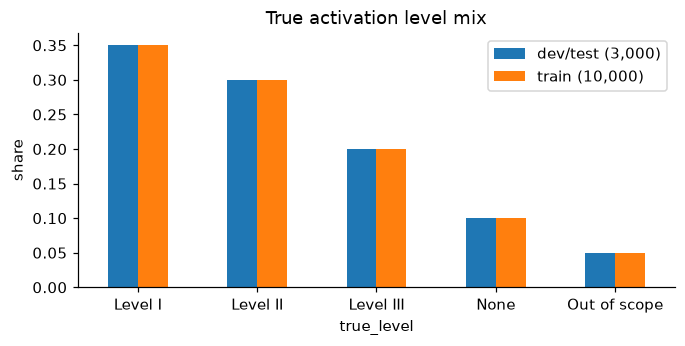

self-corrections: dev/test 19.5%, train 20.5%
borderline:       dev/test 15.2%, train 14.8%


In [11]:
order = ["1", "2", "3", "0", "out_of_scope"]
comp = pd.DataFrame({
    "dev/test (3,000)": v0.true_level.value_counts(),
    "train (10,000)": train.true_level.value_counts(),
}).reindex(order)
ax = (comp / comp.sum()).plot.bar(figsize=(7, 3), rot=0, title="True activation level mix")
ax.set_xticklabels(["Level I", "Level II", "Level III", "None", "Out of scope"]); ax.set_ylabel("share")
plt.show()
print(f"self-corrections: dev/test {v0.has_retraction.eq('True').mean():.1%}, train {train.has_retraction.eq('True').mean():.1%}")
print(f"borderline:       dev/test {v0.borderline.eq('True').mean():.1%}, train {train.borderline.eq('True').mean():.1%}")

## 5. Synthetic data, step 2: Claude rewrites (v1 → v2)

Template text is far more regular than real speech. Each dev/test case was
therefore **rewritten by Claude** into natural radio speech.

**Module: `generator/llm_paraphrase.py`.** It is not run here, because it calls the
Claude API, and the rewrites are already stored in the v1 and v2 CSVs. How it works:

| Function | Role |
|---|---|
| `facts_for(row)` | takes the **said** record and removes empty fields (`strip_nulls`). The rewriter only sees what the crew said, so it can't add facts |
| `style_for(case_id)` | picks a speaking style per case from `STYLE_POOL`: pace, fillers, structure (IMIST-AMBO order or vitals first), exchange (one report or a back-and-forth with the hospital), number style. It is seeded by case ID, so it is reproducible |
| `user_prompt(row)` | the facts plus the style, sent with a fixed `SYSTEM` instruction: "keep every fact, add nothing, write it as a real radio call" |
| `validate(row, text)` | automatic checks on each rewrite. 1) Every number in the said record must be heard in the text, in any spoken form (`heard` tries every form from `forms(n)`: "108", "one hundred eight", "one-oh-eight", ...). 2) Topics the crew did **not** say (e.g. allergies, GCS) must **not** appear; `TOPIC_WORDS` has a regex per topic. 3) A planted correction must still be there, with the wrong value said **before** the right one. 4) No markdown or speaker labels. Failed rewrites are sent back with the list of issues as feedback (`params(row, feedback)`) |

- **v1** is the first rewrite.
- **v2** is length- and style-matched to the real recordings (radio call signs,
  "copy", read-backs, hospital questions).

The same case in all three versions:

In [12]:
cid = "H00007"
for name, df in (("v0 template", v0), ("v1 rewrite", v1), ("v2 radio-style", v2)):
    print(f"--- {name} ---\n{df.set_index('case_id').loc[cid, 'text']}\n")
print("v2 style:", v2.set_index("case_id").loc[cid, "llm_style"])

--- v0 template ---
St. Mary's, Rescue 21, how copy? We're inbound to you, ETA 7 minutes. We have a 36-year-old female. Near drowning, pulled from a pool. No obvious injuries. Vitals: BP 129 over 66, heart rate 96, resps 16, sats 97 percent on room air. Airway is patent. No active bleeding. Improving en route. How copy?

--- v1 rewrite ---
Mercy, Medic 4. Go ahead. Vitals, blood pressure one hundred twenty-nine over sixty-six, heart rate ninety-six, resps sixteen, sats ninety-seven percent room air. Copy, patient? Thirty-six-year-old female, uh, near drowning. Any injuries? No obvious injuries, no active bleeding, airway's patent. She's improving with us. Seven minutes out. Copy, Medic 4.

--- v2 radio-style ---
County General, this is Medic 18, do you copy? Go ahead, Medic 18. Uh, I'll start with vitals. Blood pressure is one hundred twenty-nine over sixty-six, heart rate ninety-six, respiratory rate sixteen, and oxygen saturation ninety-seven percent on room air. Copy, one twenty-nin

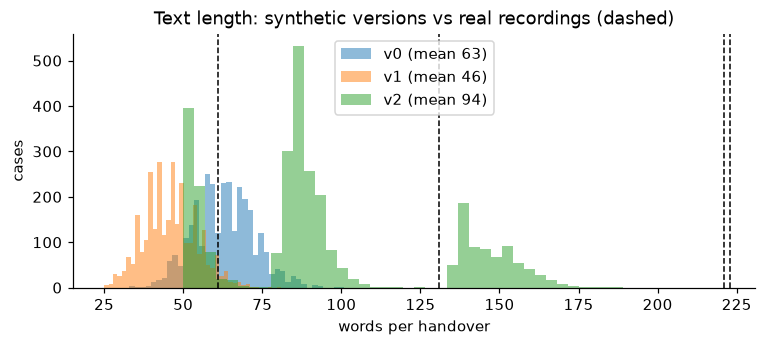

In [13]:
wc = {n: df.text.str.split().str.len() for n, df in (("v0", v0), ("v1", v1), ("v2", v2))}
fig, ax = plt.subplots(figsize=(8, 3))
for n, s in wc.items():
    ax.hist(s, bins=40, alpha=.5, label=f"{n} (mean {s.mean():.0f})")
seen = set()
for k, t in real.items():
    n = len(t.split())
    if n in seen: continue
    seen.add(n); ax.axvline(n, color="k", ls="--", lw=1)
ax.set(xlabel="words per handover", ylabel="cases", title="Text length: synthetic versions vs real recordings (dashed)")
ax.legend(); plt.show()

## 6. Train set and frozen test set

### Train set: `scripts/make_train_split.py`

There are 10,000 **template-only** cases. No Claude-written text is used for
training (decision A).
1. It keeps the extractor fully independent of the model that wrote the test texts.
2. It measures generalisation from template style to natural speech style.

How the script works:
- It calls the same generator, `generate.main(n, seed=20261027, split_mode="train", id_prefix="T")`.
  It uses a different seed from dev/test, and IDs `T00001...`, so the two sets never clash.
- `load_eval_keys()` collects every dev and test text, said record and true record
  from v0, v1 and v2 into sets.
- `clashes(row, keys)` checks a new training row against those sets. Any row that
  matches a **test** case is dropped and replaced, so the file still has exactly
  10,000 rows. Matches with **dev** are only reported.

In [14]:
import scripts.make_train_split as MTS
show_code(MTS.load_eval_keys); print(); show_code(MTS.clashes)
keys = MTS.load_eval_keys()
print("\ntrain rows clashing with a test case:", sum(bool(MTS.clashes(r, keys["test"])) for r in train.to_dict("records")))

# scripts\make_train_split.py:30
  30  def load_eval_keys():
  31      keys = {"test": {"text": set(), "said": set(), "true": set()},
  32              "dev": {"text": set(), "said": set(), "true": set()}}
  33      for name in ("v0", "v1", "v2"):
  34          for r in csv.DictReader((EX / f"synthetic_handovers_{name}.csv").open(encoding="utf-8")):
  35              k = keys[r["split"]]
  36              k["text"].add(r["text"].strip().lower())
  37              k["said"].add(r["said_record_json"])
  38              k["true"].add(r["true_record_json"])
  39      return keys

# scripts\make_train_split.py:42
  42  def clashes(r, k):
  43      return [f for f, col in (("text", "text"), ("said", "said_record_json"), ("true", "true_record_json"))
  44              if (r[col].strip().lower() if f == "text" else r[col]) in k[f]]



train rows clashing with a test case: 0


### Frozen test set: `scripts/freeze_test.py`

The 1,518 test cases and the real recordings are **frozen**. This proves that no
tuning ever touched them.

| Function | How it works |
|---|---|
| `sha(bytes)` | SHA-256 fingerprint. Any change to the input, even one character, gives a different hash |
| `row_hash(row)` | hashes `case_id + text + said record + true record` of one row |
| `build()` | for v0, v1 and v2: hashes every test row plus one hash over all of them; also hashes each real audio file and transcript |
| `main()` | without flags, writes the manifest `examples/splits/test_freeze.json`. With `--verify`, recomputes everything and prints OK or CHANGED. Re-freezing a changed set requires `--reason "..."`, and the reason, date and old/new hashes are appended to the manifest's `history` |

In [15]:
import scripts.freeze_test as FT
show_code(FT.row_hash)
print(subprocess.run([sys.executable, "scripts/freeze_test.py", "--verify"], cwd=ROOT, capture_output=True, text=True).stdout)
man = json.loads((EX / "splits" / "test_freeze.json").read_text(encoding="utf-8"))
for h in man.get("history", []):
    print(f"re-frozen {h['date']}: {h['reason']}")

# scripts\freeze_test.py:46
  46  def row_hash(r: dict) -> str:
  47      return sha("\x1f".join(r[k] for k in ROW_FIELDS).encode("utf-8"))


v0: OK
v1: OK
v2: OK
test set intact

re-frozen 2026-10-27: v2 label repair: 381 said-record corrections (155 test cases) so labels match the v2 rewrite text; true records unchanged. Log: examples/splits/v2_label_repairs.csv. Done before any model was run on test.


## 7. The rule engine: three-valued triage

**Module: `triage/engine.py`.** Imported as `from triage.engine import ...`.

The engine decides the activation level from a **said** record, where many facts
may be `null`. Ordinary True/False logic would have to treat unknown as "normal",
which can silently under-triage a patient. So every criterion returns one of three
values: `True`, `False` or `None` (unknown). The engine has four building blocks.

**1. Kleene three-valued logic** (`AND`, `OR`, `NOT`, `ANY`, `cmp`, `is_`):
- `AND` is `False` if any part is `False`, else `None` if any part is unknown, else `True`.
- `OR` is `True` if any part is `True`, else `None` if any part is unknown, else `False`.
- `NOT(None)` is `None`.
- `cmp(x, test)` applies a test such as `lambda b: b < 90`, but returns `None` when `x` is `None`.
- `is_(x, *values)` checks that `x` is one of the values, again returning `None` when `x` is unknown.

In [16]:
from triage.engine import AND, OR, NOT, cmp
show_code(AND); show_code(OR); show_code(NOT); show_code(cmp)
vals = [True, False, None]
name = {True: "True", False: "False", None: "unknown"}
pd.DataFrame([[name[a], name[b], name[AND(a, b)], name[OR(a, b)], name[NOT(a)]] for a in vals for b in vals],
             columns=["A", "B", "A AND B", "A OR B", "NOT A"])

# triage\engine.py:62
  62  def AND(*xs: Tri) -> Tri:
  63      if any(x is False for x in xs):
  64          return False
  65      return None if any(x is None for x in xs) else True
# triage\engine.py:68
  68  def OR(*xs: Tri) -> Tri:
  69      if any(x is True for x in xs):
  70          return True
  71      return None if any(x is None for x in xs) else False
# triage\engine.py:74
  74  def NOT(x: Tri) -> Tri:
  75      return None if x is None else not x
# triage\engine.py:82
  82  def cmp(x, f) -> Tri:
  83      return None if x is None else bool(f(x))


,A,B,A AND B,A OR B,NOT A
0,True,True,True,True,False
1,True,False,False,True,False
2,True,unknown,unknown,True,False
3,False,True,False,True,True
4,False,False,False,False,True
5,False,unknown,False,unknown,True
6,unknown,True,unknown,True,unknown
7,unknown,False,False,unknown,unknown
8,unknown,unknown,unknown,unknown,unknown


**2. `View`: helper questions about a record.** It wraps the record dict and
answers recurring questions with three-valued results. The documented assumptions
A1–A6 live here:
- `shock()` (A1): `True` if shock is stated or 2+ shock signs are listed; `False`
  if the crew said no shock; otherwise `None`.
- `has(pred)` (A2): `None` if injuries were never mentioned. Once a list was given,
  it is taken as complete, and the result is whether any injury matches `pred`.
- `done(*interventions)` (A3): `True` if listed, otherwise `None`. A treatment not
  mentioned is unknown, not "not done".
- `burns()` (A4), `long_bones()`, `loc_minutes()`: similar helpers for burns,
  femur/humerus fractures and loss-of-consciousness duration.

In [17]:
from triage.engine import View
show_code(View.shock); show_code(View.has); show_code(View.done)

# triage\engine.py:129
 129      def shock(self) -> Tri:                             # A1
 130          if self.s["clinical_signs_of_shock"] is True or len(self.s["shock_signs"]) >= 2:
 131              return True
 132          if self.s["clinical_signs_of_shock"] is False:
 133              return False
 134          return None
# triage\engine.py:118
 118      def has(self, pred: Callable[[dict], Tri]) -> Tri:
 119          if self.inj is None:
 120              return None
 121          return ANY([pred(i) for i in self.inj])
# triage\engine.py:114
 114      def done(self, *names) -> Tri:
 115          return True if self.tx & set(names) else None


**3. `Rule` and `RULES`: the 37 criteria as code.** Each `Rule` has an `id`, a
`level`, a `text`, a `check` function that takes a `View` and returns
True/False/None, and an `ask` question for the crew. Most checks are one line,
e.g. L1-02 = `AND(cmp(SBP, < 90), shock())`. The complex ones (L2-03 high-risk
crash, burns, ...) are separate functions such as `_l2_03`.

In [18]:
from triage.engine import RULES, Rule
print(len(RULES), "rules\n")
show_code(RULES[1].check, max_lines=3)   # the L1-02 line
pd.DataFrame([(r.id, r.level, r.text, r.ask) for r in RULES], columns=["id", "level", "criterion", "question if unknown"]).head(8)

37 rules

# triage\engine.py:260
 260           lambda x: AND(cmp(x.v["systolic_bp_mmhg"], lambda b: b < 90), x.shock()),


,id,level,criterion,question if unknown
0,L1-01,1,GCS < 9 prior to intubation,GCS?
1,L1-02,1,SBP < 90 and signs of shock,Blood pressure? Any signs of shock?
2,L1-03,1,HR > 120 and signs of shock,Heart rate? Any signs of shock?
3,L1-04,1,RR < 10 or > 29,Respiratory rate?
4,L1-05,1,SpO2 on room air < 90%,"SpO2, and is that on room air?"
5,L1-06,1,Airway compromise / advanced airway / flail chest / hemo-pneumothorax,"Is the airway patent? Any chest injury (flail chest, pneumothorax)?"
6,L1-07,1,Active or uncontrolled hemorrhage / tourniquet,"Any bleeding, and is it controlled? Tourniquet?"
7,L1-08,1,"Penetrating injury to head, neck or t-shirt/boxer area","Any penetrating injuries, and where?"


**4. `triage(record)`: the decision.**
1. It validates the record and checks scope: a stated age outside 15–64 returns
   `out_of_scope`. An unstated age is treated as adult, and the age is asked.
2. It runs every rule's `check` and sorts the IDs into **fired** (`True`) and
   **unknown** (`None`).
3. **level** = most urgent level among fired rules. 0 means no activation.
4. **possible_level** = most urgent level among fired **or unknown** rules: the
   level if every open question came back bad.
5. **ask** = questions only for unknown rules **more urgent than the current
   level**, because only those could change the decision. `URGENCY = {1: 3, 2: 2, 3: 1, 0: 0}`
   converts levels into an "urgency" number for these comparisons, since Level I
   is the most urgent and has the smallest number.
6. It returns a `Decision`. `decision.provisional` is `True` when level ≠ possible level.

`level_name(1)` just prints "Level I".

In [19]:
from triage.engine import triage, level_name, URGENCY
show_code(triage)

# triage\engine.py:383
 383  def triage(record) -> Decision:
 384      r = _canon(record)
 385      age = r["identification"]["age_years"]
 386      if age is not None and not 15 <= age <= 64:
 387          return Decision("out_of_scope", "out_of_scope",
 388                          notes=["outside 15-64: use the paediatric or geriatric criteria"])
 389      x = View(r)
 390      res = {rule.id: (rule, rule.check(x)) for rule in RULES}
 391      fired = [rid for rid, (_, v) in res.items() if v is True]
 392      unknown = [rid for rid, (_, v) in res.items() if v is None]
 393      lvl = min((res[i][0].level for i in fired), default=0)
 394      possible = min((res[i][0].level for i in fired + unknown), default=0)
 395      ceiling = URGENCY[lvl]
 396      ask = []
 397      for rid in unknown:
 398          rule = res[rid][0]
 399          if URGENCY[rule.level] > ceiling and rule.ask not in ask:
 400              ask.append(rule.ask)
 401      notes = []
 402      if age is None:
 40

In [20]:
def show(dec, title):
    extra = f"  (could be {level_name(dec.possible_level)})" if dec.provisional else ""
    print(f"{title}: {level_name(dec.level)}{extra}\n   fired: {dec.fired}")
    for q in dec.ask[:6]: print("   ask:", q)

show(triage(record), "Full handover (radio_case_001)")

partial = record.model_dump(mode="json")
partial["signs"]["vitals"] = {k: None for k in partial["signs"]["vitals"]}
partial["signs"]["gcs"] = None
show(triage(partial), "\nSame case, vitals and GCS not given")

Full handover (radio_case_001): Level II  (could be Level I)
   fired: ['L2-04', 'L2-06', 'L2-07']
   ask: Is the airway patent? Any chest injury (flail chest, pneumothorax)?
   ask: Any bleeding, and is it controlled? Tourniquet?
   ask: Moving all four limbs, sensation intact?

Same case, vitals and GCS not given: Level II  (could be Level I)
   fired: ['L2-04', 'L2-06', 'L2-07']
   ask: GCS?
   ask: Blood pressure? Any signs of shock?
   ask: Heart rate? Any signs of shock?
   ask: Respiratory rate?
   ask: SpO2, and is that on room air?
   ask: Is the airway patent? Any chest injury (flail chest, pneumothorax)?


Both decisions are **Level II, provisional**. The crew never said whether the airway
or chest is involved, so a Level I criterion is still *unknown*. The engine does not
assume "normal". It keeps the possible level at I and turns each gap into a short
question. When vitals and GCS are removed, the level stays II, but the question list
grows to include the missing vital signs.

**Validation of the engine.**
- On all 13,000 *complete* records it gives exactly the same level as the
  reference labeller `rules_full.label`. This is a unit test.
- On *incomplete* said records, the true level must always fall **between** the
  certain level and the possible level.

We check this live on the 3,000 v2 cases. `URGENCY[level] <= URGENCY[true] <= URGENCY[possible]`
means "true level lies inside the range".

In [21]:
rows = []
for _, row in v2.iterrows():
    if row.in_scope != "True": continue
    d = triage(json.loads(row.said_record_json))
    if d.level == "out_of_scope": continue
    t = int(row.true_level)
    rows.append({"bracketed": URGENCY[d.level] <= URGENCY[t] <= URGENCY[d.possible_level],
                 "under": URGENCY[d.level] < URGENCY[t], "provisional": d.provisional, "n_ask": len(d.ask)})
e = pd.DataFrame(rows)
print(f"in-scope cases: {len(e)}")
print(f"true level inside [certain, possible]: {e.bracketed.mean():.1%}")
print(f"under-triaged on certain level:        {e.under.sum()}  -> of which flagged provisional: {e[e.under].provisional.mean():.0%}")
print(f"SILENT under-triage:                   {(e.under & ~e.provisional).sum()}")
print(f"questions per case: mean {e.n_ask.mean():.1f}, max {e.n_ask.max()}")

in-scope cases: 2850
true level inside [certain, possible]: 100.0%
under-triaged on certain level:        175  -> of which flagged provisional: 100%
SILENT under-triage:                   0
questions per case: mean 3.3, max 18


**Engine assumptions A1–A6** (these need clinician sign-off):
- A1: shock = stated, or 2+ signs.
- A2: a stated injury list is complete.
- A3: unlisted interventions are unknown.
- A4: burns are `False` when another mechanism is known.
- A5: unstated arrival counts as EMS.
- A6: wrist/ankle are distal; upper arm/thigh are proximal (`schema/vocab.py`).

## 8. Prompt schema and constrained decoding

**Module: `extract/prompt_schema.py`.** Everything the language model sees is built
here, **derived automatically from `HandoverRecord`**, so the prompt can never drift
away from the schema.

| Function | How it works |
|---|---|
| `decoding_schema()` | takes Pydantic's JSON Schema, inlines every `$ref` (`_inline`), and marks **every key required** with no extra keys (`_require_all`). Ollama/vLLM use it to **constrain generation**: the model can only produce tokens that keep the output valid JSON of this shape, so it always emits the full skeleton and writes `null` for "not said" |
| `compact_schema()` | renders the same schema as a short, human-style field list (`name: type  # hint`) with hints from the `NOTES` dict. This is about 4× shorter than raw JSON Schema, which matters for small models' context windows |
| `system_prompt(examples)` | `RULES` text (null when not said, words → digits, how to log corrections, ignore radio procedure, labelling conventions) + the compact schema + optional few-shot examples |
| `messages(text, examples)` | the chat format sent to the model: a system message with the prompt, and a user message with the handover |
| `canonical(record)` | validates any record and dumps it with **every key present** (null where unsaid). Gold labels, few-shot examples and model outputs all go through it, so they are compared in exactly the same form |

In [22]:
from extract.prompt_schema import system_prompt, decoding_schema, compact_schema, messages, canonical
show_code(canonical); show_code(system_prompt); show_code(messages)

# extract\prompt_schema.py:194
 194  def canonical(record: dict) -> dict:
 195      """Validate a record and return it with every key present (null where unsaid).
 196      Used for gold labels, few-shot examples and model outputs alike."""
 197      m = HandoverRecord.model_validate(record).model_dump(mode="json")
 198      for k in DROP:
 199          m.pop(k, None)
 200      return m
# extract\prompt_schema.py:203
 203  def system_prompt(examples: list[tuple[str, dict]] | None = None) -> str:
 204      parts = [RULES, "Schema (every key must appear; null where not said):", compact_schema()]
 205      for i, (text, record) in enumerate(examples or [], 1):
 206          parts += [f"\nExample {i} handover:", text, f"Example {i} JSON:",
 207                    json.dumps(record, separators=(",", ":"))]
 208      return "\n".join(parts)
# extract\prompt_schema.py:211
 211  def messages(text: str, examples=None) -> list[dict]:
 212      return [{"role": "system", "content": system_prompt(

In [23]:
sp = system_prompt()
print(f"system prompt: {len(sp):,} chars (~{len(sp)//4:,} tokens est.); decoding schema: {len(json.dumps(decoding_schema())):,} chars\n")
print(sp[:1400], "\n...\n")
print("\n".join(compact_schema().splitlines()[:20]))

system prompt: 7,464 chars (~1,866 tokens est.); decoding schema: 9,480 chars

You convert an ambulance radio handover into one JSON object.

Rules:
1. Record only what the speaker said. If something was not mentioned, use null.
   Never fill in a normal or likely value. null means "not said", which is different
   from false or [] ("said to be absent").
2. Numbers are spoken as words or medic style ("one-oh-eight", "one twenty over
   eighty"). Write them as digits: 108, 120 and 80.
3. If the speaker corrects a value ("ninety, correction, one fifty"), put the
   corrected value in the record and add an entry to "retractions" with the field
   path, the wrong value and the corrected value, both as strings.
4. Use only the allowed values listed in the schema. Use lower_snake_case.
5. Ignore radio procedure ("how do you copy", read-backs, sign-offs) and fillers
   ("uh", "um"). A read-back by the hospital is not new information.
6. Output the JSON object only, with every key present, no 

### The exact prompt every E2 model saw

All E2 models (the 200-case screen and the full-dev finalists) get **the same two
messages** per case, built by `messages(text)` with no examples (`--fewshot 0`):

1. **system**: the full `system_prompt()` printed below. It has three parts: the 6 rules,
   the conventions for common phrases, and the compact schema.
2. **user**: the handover transcript, as is.

The run settings are the same for every model too: the JSON shape is enforced by passing
`decoding_schema()` as Ollama's `format`, with `temperature 0`, `seed 0`, at most 1,500
output tokens, and thinking off for Qwen3. Only the model changes, so the differences in
the E2 tables come from the models, not the prompt. The prompt is about 1,900 tokens; with
a typical handover the input is about 2,400 tokens per case.

In [24]:
dev_case = pd.read_csv(ROOT / "examples" / "synthetic_handovers_v2.csv").set_index("case_id").loc["H00002"]
msgs = messages(dev_case.text)
for m in msgs:
    print(f"===== {m['role']} message ({len(m['content']):,} chars) =====")
    print(m["content"], "\n")

===== system message (7,464 chars) =====
You convert an ambulance radio handover into one JSON object.

Rules:
1. Record only what the speaker said. If something was not mentioned, use null.
   Never fill in a normal or likely value. null means "not said", which is different
   from false or [] ("said to be absent").
2. Numbers are spoken as words or medic style ("one-oh-eight", "one twenty over
   eighty"). Write them as digits: 108, 120 and 80.
3. If the speaker corrects a value ("ninety, correction, one fifty"), put the
   corrected value in the record and add an entry to "retractions" with the field
   path, the wrong value and the corrected value, both as strings.
4. Use only the allowed values listed in the schema. Use lower_snake_case.
5. Ignore radio procedure ("how do you copy", read-backs, sign-offs) and fillers
   ("uh", "um"). A read-back by the hospital is not new information.
6. Output the JSON object only, with every key present, no comments and no extra text.

Conventio

## 9. Scoring

**Module: `extract/score.py`.** It compares each predicted record with the gold
**said** record. A model's raw output is scored by the same code whether it comes
from the regex baseline, an SLM, or a test.

| Function | How it works |
|---|---|
| `parse_output(raw)` | strips code fences, takes the outermost `{...}`, parses the JSON, validates it with `canonical`. If validation fails, it tries `repair` (section 9b). Returns the record plus a status: `valid`, `repaired`, `invalid_json` or `invalid_schema`. Invalid outputs are scored as an empty record |
| `LEAVES` / `get(rec, path)` | the list of every leaf field path in the schema (e.g. `signs.vitals.heart_rate_bpm`), and a function that reads a path from a record |
| `norm(v)` | normalises a value before comparing: numbers as floats, text lower-cased, dicts sorted |
| `compare_case(gold, pred)` | gives each field one of the outcomes below. **List fields** (injuries, medications, ...) are compared as multisets, so order doesn't matter |
| `level_of(rec)` / `triage_outcome(g, p)` | runs the **engine** on gold and predicted records, and labels the result correct, under (less urgent), over, or scope_error |
| `correction_ok(gold, pred)` | for cases with a planted correction: is the corrected value right **and** the retraction logged? |
| `summarise(cases)` | turns per-case outcomes into the metrics, including `valid_rate` (strictly valid) and `usable_rate` (valid or repaired) |
| `bootstrap(cases)` | 95% confidence intervals: recompute the metrics on 1,000 random resamples of the cases |
| `score(pred_path, gold_path, split)` | the whole pipeline: load predictions + gold → parse → compare → triage → summarise → report dict |

The field outcomes:

| outcome | meaning |
|---|---|
| correct | same value |
| wrong | both have a value, but they differ |
| missed | gold has a value, prediction is null |
| **hallucinated** | gold is null (not said), prediction invents a value |
| ok_null | both null |

- precision = correct / (correct + wrong + hallucinated)
- recall = correct / (correct + wrong + missed)
- hallucination rate = hallucinated / (hallucinated + ok_null)
- **silent under-triage** = under-triaged *and* the engine did not flag the decision as provisional

In [25]:
from extract.score import score, compare_case, parse_output
show_code(parse_output); show_code(compare_case, max_lines=40)

# extract\score.py:72
  72  def parse_output(raw: str, fixes: list | None = None):
  73      """Return (record or None, status) with status in valid/repaired/invalid_json/invalid_schema.
  74  
  75      "repaired": the JSON broke a cross-field rule of the schema and was made valid by
  76      extract/postprocess.repair (which only nulls or drops contradicting details).
  77      The names of the fixes are appended to `fixes` if a list is given."""
  78      if raw is None:
  79          return None, "invalid_json"
  80      s = re.sub(r"^```(?:json)?|```$", "", raw.strip(), flags=re.M).strip()
  81      a, b = s.find("{"), s.rfind("}")
  82      if a < 0 or b < a:
  83          return None, "invalid_json"
  84      try:
  85          obj = json.loads(s[a:b + 1])
  86      except json.JSONDecodeError:
  87          return None, "invalid_json"
  88      obj.pop("schema_version", None)
  89      try:
  90          return canonical(obj), "valid"
  91      except Exception:
  92          

Sanity check: a perfect model (it echoes the gold record) and an empty model on 100
dev cases. The prediction file format is one JSON line per case,
`{"case_id": ..., "output": "<raw model text>"}`.

In [26]:
tmp = pathlib.Path(tempfile.mkdtemp())
dev100 = v2[v2.split == "dev"].head(100)
def write(path, outputs):
    with open(path, "w", encoding="utf-8") as fh:
        for cid, out in outputs: fh.write(json.dumps({"case_id": cid, "output": out}) + "\n")
write(tmp / "gold.jsonl", zip(dev100.case_id, dev100.said_record_json))
write(tmp / "empty.jsonl", ((c, "{}") for c in dev100.case_id))
keys = ["valid_rate", "field_f1", "hallucination_rate", "exact_match", "triage_accuracy", "under_triage_rate", "silent_under_triage_rate"]
res = {n: score(tmp / f"{n}.jsonl", EX / "synthetic_handovers_v2.csv", "dev", subset=True)[0]["overall"] for n in ("gold", "empty")}
pd.DataFrame(res).loc[keys].round(3)

,gold,empty
valid_rate,1.0,1.0
field_f1,1.0,0.0
hallucination_rate,0.0,0.0
exact_match,1.0,0.0
triage_accuracy,1.0,0.12
under_triage_rate,0.0,0.83
silent_under_triage_rate,0.0,0.0


The **empty model** has 0 F1 and under-triages 83% of cases. Its silent under-triage is
still 0, because an empty record leaves every criterion *unknown*, so every decision
is flagged as provisional. This is why silent under-triage is always reported
**together with** the provisional rate and the number of questions. Asking about
everything is safe but useless.

## 9b. Repairing outputs that break cross-field rules

**Module: `extract/postprocess.py`.** Added after the first real model run.

**Why it is needed.** Constrained decoding guarantees the JSON **shape**: every
key, and only allowed enum values. But the schema also has **cross-field rules**
(the Pydantic validators from section 1) that a JSON grammar cannot express. On
its first 5 dev cases, qwen3:1.7b produced 3 records that broke such a rule:
- `"bone": "femur"` on a *pulseless limb* injury (only fractures have a bone);
- vehicle details on an *assault*;
- intubation listed while the airway was "patent".

Without repair, one slip discards the whole record.

**How it works.**

| Function | Role |
|---|---|
| `targeted(obj)` | one fix per validator, mirroring it: bone/open/depressed fields on a non-fracture → null; GCS components that don't sum to the total → components null (total kept); diastolic > systolic → diastolic null; intubation with a non-advanced airway status → airway null; tourniquet with "no bleeding" → bleeding null; and so on. A limb-only injury on a non-limb region is dropped. Returns the list of fixes made |
| `_null_at(obj, loc)` | for anything still invalid, such as a number outside its range (e.g. age 400), sets that **leaf** to null. Whole sections are never nulled |
| `repair(obj)` | validate; if that fails, apply `targeted`, then null leftover leaves (up to 10 rounds). Returns `(record or None, fixes)` |

**The principle:** a repair **never invents a value**. It only turns a contradicting
detail into `null`, i.e. "not said". The rule engine then treats it as unknown and
asks about it, so a repair can make a decision *provisional* but never silently
lower it. The scorer keeps the model honest by reporting **both** `valid_rate`
(no repair needed) and `usable_rate` (after repair), plus counts of each fix.

In [27]:
from extract.postprocess import repair, targeted
show_code(targeted, max_lines=30)

# extract\postprocess.py:44
  44  def targeted(obj: dict) -> list[str]:
  45      """Apply the validator-mirroring fixes in place; return the names of the fixes made."""
  46      fixes = []
  47      ident, mech, signs = _d(obj.get("identification")), _d(obj.get("mechanism")), _d(obj.get("signs"))
  48      vit, tx = _d(signs.get("vitals")), _d(obj.get("treatment"))
  49  
  50      def fix(name, cond, action):
  51          if cond:
  52              action()
  53              fixes.append(name)
  54  
  55      # identification
  56      fix("gestation_without_pregnancy", ident.get("gestation_weeks") is not None and ident.get("pregnant") is not True,
  57          lambda: ident.update(gestation_weeks=None))
  58      fix("pregnant_male", ident.get("pregnant") is True and ident.get("sex") == "male",
  59          lambda: ident.update(pregnant=None, gestation_weeks=None))
  60  
  61      # mechanism
  62      fall, loc = _d(mech.get("fall")), _d(mech.get("loss_of_consciousness"))
  6

In [28]:
raw = {"mechanism": {"type": "assault_blunt", "vehicle": {"impact_speed_mph": 30}},
       "injuries": [{"type": "pulseless_extremity", "region": "thigh", "bone": "femur", "digits_involved": 1}],
       "signs": {"airway": "patent", "gcs": {"eye": 4, "verbal": 5, "motor": 5, "total": 15}},
       "treatment": {"interventions": ["endotracheal_intubation"]}}
fixed, fixes = repair(raw)
print("fixes:", fixes)
print("mechanism.vehicle:", fixed["mechanism"]["vehicle"], "| injury:", {k: v for k, v in fixed["injuries"][0].items() if v is not None})
print("airway:", fixed["signs"]["airway"], "| gcs:", fixed["signs"]["gcs"])
print("parse_output status:", parse_output(json.dumps(raw))[1])

fixes: ['vehicle_details_wrong_mechanism', 'fracture_fields_on_non_fracture', 'digits_not_amputation', 'gcs_components_mismatch', 'advanced_airway_status_conflict']
mechanism.vehicle: None | injury: {'type': 'pulseless_extremity', 'region': 'thigh'}
airway: None | gcs: {'eye': None, 'verbal': None, 'motor': None, 'total': 15, 'before_intubation': None}
parse_output status: repaired


## 10. E0: regex baseline (the floor to beat)

**Module: `extract/regex_baseline.py`.** This extractor uses no model: hand-written
rules only.

| Function | How it works |
|---|---|
| `words_to_digits(text)` | lower-cases the text and converts spoken numbers to digits, including medic style: "one twenty-four" → 124, "one-oh-five" → 105, "one hundred twenty" → 120 (helpers `_number`, `_two_digit`) |
| `extract(text)` | 1) runs `words_to_digits`; 2) **collapses corrections**: a regex finds "*number*, correction / sorry / I mean, *number*", keeps the second number and logs a retraction; 3) fills each field with patterns, e.g. age from "(\d+) year old", ETA from "eta ... (\d+)" or "(\d+) minutes out", mechanism from a keyword table, injuries from bone/region word lists; 4) returns a full record (starting from `canonical({})`, all null) |
| `first(pattern, s)` | the first regex match converted to a number, or `None` |
| `main()` | runs `extract` on a split and writes predictions in the same JSONL format as the model runs, so `score.py` treats it the same way |

This is a strong floor, because its vocabulary comes from the generator. A real
system would not know the closed word lists. The real test is whether SLMs beat it
on messy speech and generalise beyond it.

Live run on the hand-written example:

In [29]:
from extract.regex_baseline import extract, words_to_digits
show_code(extract, max_lines=22)

# extract\regex_baseline.py:162
 162  def extract(text: str) -> dict:
 163      s = words_to_digits(text)
 164      rec = canonical({})
 165      I, M, S, V = rec["identification"], rec["mechanism"], rec["signs"], rec["signs"]["vitals"]
 166  
 167      # self-corrections: "120, correction, 90" -> keep 90, remember the pair
 168      corrections = []
 169  
 170      def _fix(m):
 171          corrections.append((m.group(1), m.group(2), m.start()))
 172          return m.group(2)
 173      s = re.sub(r"(\d+)(?:[ ,.]+(?:uh|um|sorry|wait))*[ ,.]+(?:correction|sorry|i mean|scratch that)[ ,.]+(?:(?:uh|um)[ ,.]+)*(\d+)",
 174                 _fix, s)
 175  
 176      # I
 177      I["age_years"] = first(r"(\d+)[- ]year[- ]old", s)
 178      sx = first(r"year[- ]old (male|female)", s, cast=str) or first(r"\b(male|female)\b", s, cast=str)
 179      I["sex"] = sx
 180      I["arrival_mode"] = "ems_interfacility" if "interfacility" in s or "transfer from" in s else "ems_scene"
 181      if re.s

In [30]:
print(words_to_digits("bp one twenty-four over eighty, heart rate one-oh-five, sats ninety-four percent"))
pred = canonical(extract(text))
fields, _ = compare_case(canonical(record.model_dump(mode='json')), pred)
print("\nfield outcomes on radio_case_001:", dict(collections.Counter(fields.values())))
print("not right:", [f for f, o in fields.items() if o in ("wrong", "missed", "hallucinated")])
show(triage(pred), "\nengine on regex output")

bp 124 over 80, heart rate 105, sats 94 percent

field outcomes on radio_case_001: {'correct': 20, 'ok_null': 28, 'missed': 6, 'wrong': 2}
not right: ['mechanism.type', 'mechanism.description', 'mechanism.vehicle.impact_speed_mph', 'mechanism.vehicle.patient_thrown', 'mechanism.vehicle.rider_separated', 'mechanism.loss_of_consciousness.duration_minutes', 'injuries', 'treatment.interventions']

engine on regex output: Level II  (could be Level I)
   fired: ['L2-06', 'L2-07']
   ask: Is the airway patent? Any chest injury (flail chest, pneumothorax)?
   ask: Any bleeding, and is it controlled? Tourniquet?
   ask: Moving all four limbs, sensation intact?
   ask: Burn size (% BSA)? Any inhalation injury? Other injuries?


The full E0 run was produced from the command line, then scored:
```bash
python -m extract.regex_baseline --split dev --out runs/e0_regex_v2_dev.jsonl
python -m extract.score runs/e0_regex_v2_dev.jsonl --split dev --out runs/e0_regex_v2_dev.report.json
```
Here we load the saved report.

In [31]:
rep = json.loads((ROOT / "runs" / "e0_regex_v2_dev.report.json").read_text(encoding="utf-8"))
o, ci = rep["overall"], rep["ci95"]
pd.DataFrame({m: {"value": o[m], "95% CI": f"{ci[m][0]:.3f}-{ci[m][1]:.3f}" if m in ci else ""} for m in keys}).T.round(3)

,value,95% CI
valid_rate,1.0,1.000-1.000
field_f1,0.990269,0.989-0.991
hallucination_rate,0.000126,0.000-0.000
exact_match,0.302294,0.279-0.325
triage_accuracy,0.952767,0.943-0.964
under_triage_rate,0.047233,0.036-0.057
silent_under_triage_rate,0.0,0.000-0.000


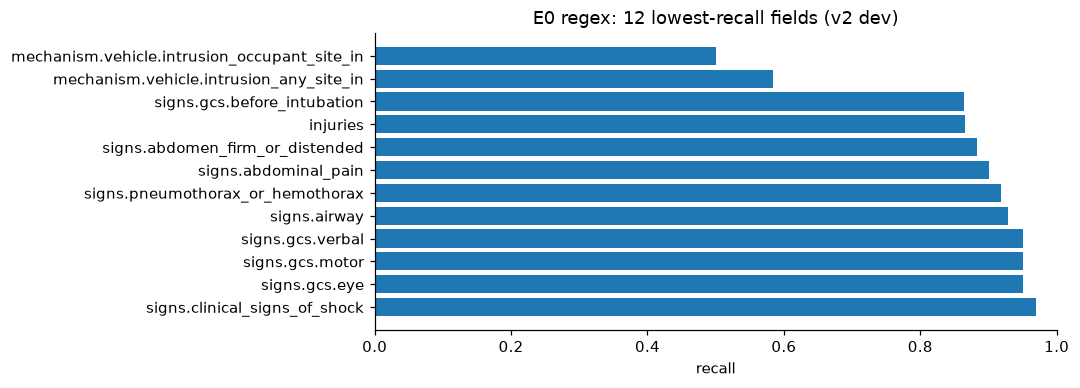

,pred 1,pred 2,pred 3,pred 0,pred out_of_scope
gold 1,485,7,0,16,0
gold 2,0,428,3,12,0
gold 3,0,0,202,32,0
gold 0,0,0,0,228,0
gold out_of_scope,0,0,0,0,69


In [32]:
pf = pd.DataFrame(rep["per_field"]).T
low = pf.dropna(subset=["recall"]).sort_values("recall").head(12)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(low.index, low.recall); ax.invert_yaxis(); ax.set_xlim(0, 1)
ax.set(title="E0 regex: 12 lowest-recall fields (v2 dev)", xlabel="recall"); plt.show()

conf = collections.Counter(rep["triage_confusion"])
lv = ["1", "2", "3", "0", "out_of_scope"]
pd.DataFrame([[conf.get(f"{g}->{p}", 0) for p in lv] for g in lv],
             index=[f"gold {l}" for l in lv], columns=[f"pred {l}" for l in lv])

**Reading E0.**
- Field F1 is about 0.99, but only about 30% of records are exactly right.
- Most errors are in **injuries** and **vehicle intrusion**, the most free-form parts of speech.
- Every under-triage case is **flagged as provisional**: silent under-triage = 0.
  The three-valued engine protects even a weak extractor.

### 10b. Why E0 is optimistic, and where it breaks

E0 scores F1 0.99 on v2 dev, but that number flatters it. Its word lists and sentence
patterns were written **from our own generator**: the same drug names, injury words and
phrasings (for example "BP 90 over 60", "laceration to the forearm", "on apixaban").
The Claude v2 rewrites keep most of that vocabulary, so on synthetic text the regex is
matching phrasing it was written for. A real crew does not talk like our templates.

The models had none of this inside knowledge: they only saw the prompt. So "regex 0.99
vs Qwen3 4B 0.85" does **not** mean the regex is the better extractor. It means that
on text built from our own vocabulary, hand-written rules win.

**Test 1: the same facts, said differently.** Each line below is our own example
sentence (not from any dataset). The first uses generator wording; the others say the
same kind of thing the way crews often do.

In [33]:
probes = [
    ("generator wording",        "45-year-old male, MVC at 40 mph. BP 90 over 60, heart rate 120, sats 95 on room air. On apixaban."),
    ("vitals without labels",    "45-year-old male, car crash. Vitals one-ten over seventy, a hundred and twenty, ninety-five percent."),
    ("brand-name drug",          "45-year-old male, car crash, takes Eliquis. BP 110 over 70."),
    ("slang 'thinners'",         "45-year-old male, car crash, he's on blood thinners. BP 110 over 70."),
    ("'satting'",                "45-year-old male, car crash, satting ninety-one on a non-rebreather."),
    ("'pressure's'",             "45-year-old male, car crash, pressure's ninety over fifty, pulse one-thirty."),
    ("'approximately N years'",  "Male, approximately thirty-five years old, motor vehicle crash."),
    ("'bruising'",               "45-year-old male, car crash, bruising across the chest."),
]
rows = []
for name, t in probes:
    r = extract(t); v = r["signs"]["vitals"]
    rows.append({"phrasing": name, "age": r["identification"]["age_years"],
                 "BP": f"{v['systolic_bp_mmhg']}/{v['diastolic_bp_mmhg']}" if v["systolic_bp_mmhg"] else None,
                 "HR": v["heart_rate_bpm"], "SpO2": v["spo2_percent"],
                 "meds": r["medications"], "injuries": r["injuries"]})
pd.DataFrame(rows, dtype=object).fillna("-")

,phrasing,age,BP,HR,SpO2,meds,injuries
0,generator wording,45,90/60,120,95,[apixaban],-
1,vitals without labels,45,-,-,-,-,-
2,brand-name drug,45,110/70,-,-,-,-
3,slang 'thinners',45,110/70,-,-,-,-
4,'satting',45,-,-,-,-,-
5,'pressure's',45,-,130,-,-,-
6,'approximately N years',-,-,-,-,-,-
7,'bruising',45,-,-,-,-,-


Only the first line, in generator wording, comes out complete. Every other line loses
the facts that were said in a new way: BP, heart rate and SpO2 without the expected
label, "Eliquis" or "thinners" instead of a listed drug name, "satting", "pressure's",
"approximately 35 years old", "bruising".

**Test 2: the 3 real recordings.** These are the Whisper transcripts of the real radio
handovers (section 3). They have no labels, so there is no score here, only a look at
what the regex fills in.

> **Test-set note.** The real recordings belong to the frozen test set, which is scored
> once, in E6. Here we only run the regex, which is fixed: it will **not** be changed
> because of what we see below (recorded in `docs/pipeline_status.txt`). No model is
> run on these recordings before E6.

In [34]:
def filled(rec, prefix=""):
    # the fields the extractor filled in (not null)
    out = {}
    for k, v in rec.items():
        if isinstance(v, dict):
            out.update(filled(v, prefix + k + "."))
        elif v is not None and v != []:
            out[prefix + k] = v
    return out

for name in ["sample_audio_flac", "test_mp4", "Test_sample_flac"]:
    tp = ROOT / "examples" / "transcripts" / f"{name}.txt"
    if not tp.exists():                                  # transcripts are kept out of git
        print(f"== {name}: transcript not present, skipped")
        continue
    t = tp.read_text(encoding="utf-8")
    f = filled(extract(t))
    f.pop("identification.arrival_mode", None)          # always defaulted, not read from the text
    print(f"== {name}  ({len(t.split())} words, {len(f)} fields filled)")
    for k, v in f.items():
        print(f"   {k:42s} {v}")

== sample_audio_flac  (61 words, 5 fields filled)
   identification.age_years                   84
   identification.sex                         male
   identification.eta_minutes                 5
   mechanism.loss_of_consciousness.occurred   False
   signs.gcs.total                            15
== test_mp4  (131 words, 11 fields filled)
   identification.age_years                   78
   identification.sex                         female
   identification.eta_minutes                 5
   signs.vitals.systolic_bp_mmhg              100
   signs.vitals.diastolic_bp_mmhg             60
   signs.vitals.heart_rate_bpm                105
   signs.vitals.resp_rate_per_min             22
   signs.vitals.spo2_percent                  92
   signs.vitals.spo2_on_room_air              False
   signs.gcs.total                            12
   signs.abdomen_firm_or_distended            True
== Test_sample_flac  (221 words, 11 fields filled)
   identification.sex                         male
   mech

**What was said but missed** (read by hand from the transcripts above):

| Recording | Said | Regex result | Why it broke |
|---|---|---|---|
| sample_audio (61 words) | "restrained driver with airbag deployment" | no mechanism | no keyword like "MVC" or "crash" |
| | "110 over 70, 70 heart rate, 99% on room air" | **no vitals at all** | number said **before** its label, or no "BP" label |
| | "laceration to forehead" | no injury | "forehead" is not in the region list |
| | "on blood thinners" | no medication | only listed drug names are known |
| test_mp4 (131 words) | "high-speed auto crash", "extrication over 25 minutes" | no mechanism, no extrication | "auto crash" is not a keyword; vehicle details are only read for a known vehicle mechanism |
| | "seatbelt sign across her chest and abdomen" | no injury | the pattern expects "across **the** chest", not "across **her** chest" |
| | laceration to forehead, blood thinners | missed | same as above |
| Test_sample (221 words) | "approximately 35 years old" | no age | the pattern needs "35-year-old" |
| | "Blood pressure is 100 over 70" | **no BP** | a line break between "pressure" and "is" breaks the pattern |
| | "rule over" (Whisper's mishearing of "rollover") | no rollover | spelling error from speech recognition |
| | "cool and diverted" (mishearing of "diaphoretic"), weak pulses | no shock signs | spelling error; "weak but palpable" is not "weak thready pulse" |
| | "no externally bleeding", "bruising around abdomen and chest" | no bleeding status, no injury | unusual grammar; "bruising" is not a listed word |

It does get the parts said in the expected way: age as "84 year old", GCS, ETA, "no loss
of consciousness", and fully labelled vitals in `test_mp4`.

**What this means for the thesis.**
- E0's 0.99 is an **upper bound for pattern matching on our own vocabulary**, not a
  measure of how hard the task is.
- On real speech it misses vitals, mechanism and injuries, which are exactly the
  inputs triage depends on. The engine would still flag them as unknown and ask
  (no silent under-triage), but the crew would get many unnecessary questions.
- An SLM reads meaning rather than fixed strings, so it should hold up better on new
  phrasing, brand names and speech-recognition errors. That is tested properly in E6
  (real recordings, run once) and E7 (synthetic speech passed through Whisper).

## 11. Label audit and repair (v2)

A careful check found **label noise**. The v2 rewrite sometimes *dropped* a
statement that the label still had (e.g. "no obvious injuries") or *added* one
that the label lacked ("signs of shock", "stable").

**`scripts/audit_v2_labels.py`** proposes fixes:
- `words_to_digits` (from the regex baseline) normalises the text first.
- `propose(case_id, text, gold)` runs one detector per topic: injuries, GCS, airway,
  pneumothorax, bleeding, trend, abdomen, neuro, LOC, shock, ETA, AMBO lists,
  interventions, SpO2, corrections. Each detector asks two questions:
  - *the label has a value, but is the topic mentioned at all?* If not, it proposes `null`.
  - *the label is null, but does the crew state it?* If so, it proposes the value.
- `crew_says(text, pattern)` ignores sentences starting with "copy". Those are the
  hospital reading back, not the crew stating something.
- The output, `runs/v2_label_candidates.csv`, holds one proposal per row with the
  text snippet that justifies it.

**Every proposal was then reviewed by hand.**

**`scripts/repair_v2_labels.py`** applies the decisions:
- `REJECT` holds the 16 proposals rejected after reading the text, with reasons.
  These were detector false positives, e.g. "allergies? none known" or "diabetic".
- `apply(said, field, old, new)` edits the said record for one accepted proposal.
- Each edited record is re-validated with `canonical`. Only **said** records change:
  the true record describes the patient, not the text.
- Every change is logged to `examples/splits/v2_label_repairs.csv`, and the original
  file is backed up. The script refuses to run twice.

The test set was then re-frozen with the reason recorded (section 6). All of this
was done before any model saw the test set.

In [35]:
import scripts.audit_v2_labels as AUD, scripts.repair_v2_labels as REP
show_code(AUD.crew_says); show_code(AUD.propose, max_lines=20); show_code(REP.apply)

# scripts\audit_v2_labels.py:43


  43  def crew_says(text, pat):
  44      """True if pat appears in a sentence that is not a hospital read-back ('copy, ...')."""
  45      return any(not re.match(r"^(?:uh,? |um,? )*copy\b", s) for s in sentences(text, pat))
# scripts\audit_v2_labels.py:48
  48  def propose(cid, t, g):
  49      """Yield (field, old, new, reason, snippet)."""
  50      S, I, M = g["signs"], g["identification"], g["mechanism"]
  51  
  52      # ---------------- injuries
  53      inj_pat = (r"no (?:other |obvious |visible )?injur|no injuries|injur(?:y|ies)? (?:noted|found)"
  54                 r"|none obvious|none found|none other|nothing we've found|nothing obvious"
  55                 r"|injuries\?\s*(?:(?:uh|um),?\s*)*(?:none|no|nothing)")
  56      if g["injuries"] == [] and not re.search(inj_pat, t):
  57          yield "injuries", "[]", "null", "'no injuries' not said in v2", snip(t, r"injur")
  58      if g["injuries"] is None and re.search(r"no (?:other |obvious |visible )?injuries", t):
 

# scripts\repair_v2_labels.py:57
  57  def apply(said, field, old, new):
  58      S, I, M = said["signs"], said["identification"], said["mechanism"]
  59      val = None if new == "null" else json.loads(new) if new not in ("remove", "false/false") else new
  60      if field == "injuries":
  61          said["injuries"] = val
  62      elif field == "signs.gcs.components":
  63          S["gcs"].update(eye=None, verbal=None, motor=None)
  64      elif field == "signs.abdomen":
  65          S["abdominal_pain"] = S["abdomen_firm_or_distended"] = None
  66      elif field == "signs.neuro":
  67          S["paralysis"] = S["bilateral_sensory_loss"] = None
  68      elif field == "mechanism.loss_of_consciousness":
  69          M["loss_of_consciousness"] = None
  70      elif field == "identification.eta_minutes":
  71          I["eta_minutes"] = None
  72      elif field == "signs.vitals.spo2":
  73          S["vitals"]["spo2_percent"] = S["vitals"]["spo2_on_room_air"] = None
  74      e

decision
applied     381
rejected     16 

cases changed: 311 | dev/test: {'dev': 156, 'test': 155}


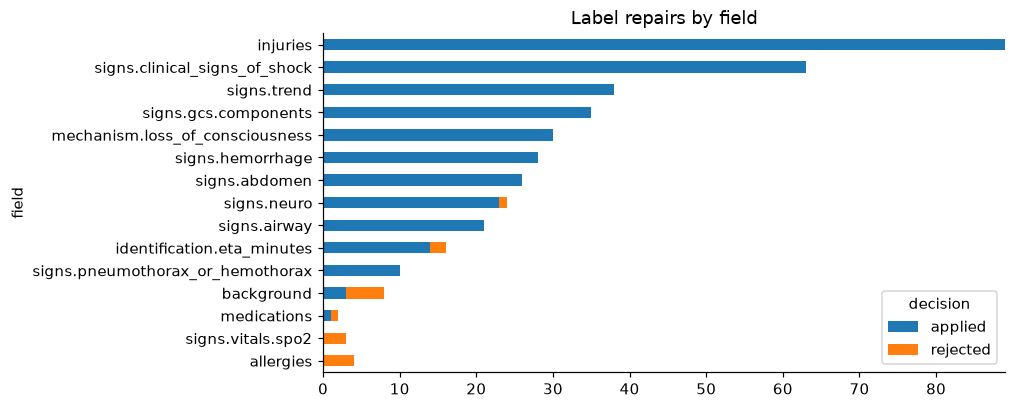

,case_id,field,old,new,reason
5,H00022,signs.vitals.spo2,98,null,SpO2 given as 'N percent' in the vitals list
12,H00029,signs.neuro,None/None,false/false,'moving all four?' is the hospital's question; crew does not answer
21,H00203,background,diabetes,remove,text says 'diabetic' (detector looked for 'diabetes')
22,H00203,signs.vitals.spo2,98,null,SpO2 given as 'N percent' in the vitals list
25,H00236,signs.vitals.spo2,95,null,SpO2 given as 'N percent' in the vitals list
34,H00339,background,diabetes,remove,text says 'diabetic' (detector looked for 'diabetes')
36,H00374,background,diabetes,remove,text says 'diabetic' (detector looked for 'diabetes')
40,H00398,background,diabetes,remove,text says 'diabetic' (detector looked for 'diabetes')


In [36]:
log = pd.read_csv(EX / "splits" / "v2_label_repairs.csv", dtype=str, keep_default_na=False)
print(log.decision.value_counts().to_string(), "\n")
print("cases changed:", log[log.decision == 'applied'].case_id.nunique(),
      "| dev/test:", log[log.decision == 'applied'].drop_duplicates('case_id').split.value_counts().to_dict())
tab = log.groupby(["field", "decision"]).size().unstack(fill_value=0).sort_values("applied")
tab.plot.barh(stacked=True, figsize=(8, 4), title="Label repairs by field"); plt.show()
log[log.decision == "rejected"][["case_id", "field", "old", "new", "reason"]].head(8)

**Effect on E0 (dev):**

| | field F1 | exact match | triage accuracy | under-triage |
|---|---|---|---|---|
| before repair | 0.986 | 26.5% | 93.5% | 6.4% |
| after repair | 0.990 | 30.2% | 95.3% | 4.7% |

Part of the earlier "error" was noise in the labels, not in the extractor.

## 12. Inference harness (Ollama installed, E2 done)

**Module: `extract/run.py`.** It runs a language model over a split and writes
predictions in the format `score.py` reads.

| Part | How it works |
|---|---|
| `Ollama` | backend for a local **Ollama** server. Calling it with `messages` sends a POST to `/api/chat` with `temperature 0` and `seed 0` (deterministic), `format` = `decoding_schema()` (constrained JSON), optional `think` on/off for reasoning models such as Qwen3, and an output cap of 1,500 tokens (`num_predict`, flag `--max-tokens`) so a runaway generation stops quickly. Returns the text and token counts |
| `OpenAICompat` | the same for any OpenAI-compatible server (vLLM, llama.cpp server, LM Studio), using `response_format: json_schema`. This is for running bigger models on university HPC or cloud GPUs |
| `GoldEcho` | a fake backend that returns the gold record. It tests the plumbing without a model |
| `pick_examples(k)` | few-shot examples, **always taken from the train set** (never dev/test): one with a correction, one with injuries, then random |
| `main()` | loads the split, builds the prompt, calls the backend for each case, logs output, latency and tokens to `runs/<model>_<split>_k<k>.jsonl`. The run is **resumable**: cases already in the file are skipped. A `.meta.json` file stores the settings and a hash of the prompt |

**`scripts/sweep.py`** loops over a list of 12 small models. For each one it runs
`ollama pull`, then a 50-case smoke test. It stops if under 80% of outputs are
usable or the mean time per case is over 120 s. Otherwise it continues to **200 dev cases**,
scores the model and appends a row to `runs/sweep_dev_k0.csv`. It refuses to run
on the test split.

Why 200 cases and not all of dev? On the laptop GPU, a 1.7B model takes about **6 s
per handover**: about 2,450 prompt tokens, plus about 550 output tokens because
the full JSON skeleton is always written. Full dev (1,482 cases) is about 2.5 h
per model, so all 12 models are screened on the same 200 cases. Dev order is
already random, so this is a random sample. The best 3–4 then get the full dev
split (`--limit 0`).

```bash
python -m extract.run --backend ollama --model qwen3:4b --split dev --think off
python scripts/sweep.py                      # E2 zero-shot over 12 small models
python -m extract.score runs/qwen3-4b_dev_k0.jsonl --split dev
```

In [37]:
from extract.run import Ollama, pick_examples
show_code(Ollama.__call__); show_code(pick_examples)

# extract\run.py:50
  50      def __call__(self, msgs):
  51          body = {"model": self.model, "messages": msgs, "stream": False,
  52                  "options": {"temperature": 0, "seed": 0, "num_ctx": self.num_ctx,
  53                              "num_predict": self.max_tokens}}   # a runaway stops here, scored invalid
  54          if self.constrained:
  55              body["format"] = decoding_schema()
  56          if self.think is not None:                       # reasoning models (Qwen3 etc.)
  57              body["think"] = self.think
  58          r = self.client.post(self.url, json=body)
  59          r.raise_for_status()
  60          j = r.json()
  61          return j["message"]["content"], {"prompt_tokens": j.get("prompt_eval_count"),
  62                                           "output_tokens": j.get("eval_count")}
# extract\run.py:93
  93  def pick_examples(k, source, seed=0):
  94      if k <= 0:
  95          return []
  96      path = ROOT / "examples" / (

The plumbing test below uses the gold-echo backend on 5 dev cases:

In [38]:
out = tmp / "gold_echo.jsonl"
r = subprocess.run([sys.executable, "-m", "extract.run", "--backend", "gold", "--split", "dev", "--limit", "5", "--out", str(out)],
                   cwd=ROOT, capture_output=True, text=True)
print(r.stdout[-300:])
ex = pick_examples(2, "train")
print("few-shot example texts (from TRAIN):", [t[:60] + "..." for t, _ in ex])
print("roles in one request:", [m["role"] for m in messages("…handover text…", ex)])

ady done, 5 to run -> C:\Users\a.ali\AppData\Local\Temp\tmp2m543awi\gold_echo.jsonl
  5/5  last 0.0s  errors 0
done. score with: python -m extract.score C:\Users\a.ali\AppData\Local\Temp\tmp2m543awi\gold_echo.jsonl --gold C:\Users\a.ali\radio-to-resus\examples\synthetic_handovers_v2.csv --split dev



few-shot example texts (from TRAIN): ['Mercy, Medic 30, come in. We have a eight, I mean, eighteen-...', "University Hospital, Medic 18, how copy? We're inbound to yo..."]
roles in one request: ['system', 'user']


---
# Part 2: Future work (MOCK-UPS)

> ⚠️ **Everything below uses invented placeholder numbers.** These cells show
> *what* each planned experiment measures and *how* the result will be shown.
> They are **not results**.

**How the mock cells work.** `load_or_mock(path, mock_fn)` first looks for the
experiment's real results file in `runs/`. If the file exists, it loads it and
prints "REAL RESULTS". Otherwise it calls `mock_fn()`, which generates placeholder
numbers from a fixed seed, and prints "MOCK DATA". `mock_banner` draws a red "MOCK"
watermark on charts made from mock data. Re-running the notebook after the
experiments replaces the mocks automatically.

In [39]:
MOCK = random.Random(2026)
def load_or_mock(path, mock_fn):
    p = ROOT / path
    if p.exists():
        print(f"REAL RESULTS from {path}")
        return pd.read_csv(p), False
    print(f"MOCK DATA (no {path} yet): placeholder values for illustration only")
    return mock_fn(), True
def mock_banner(ax, is_mock):
    if is_mock:
        ax.text(.5, .5, "MOCK", transform=ax.transAxes, fontsize=60, color="red", alpha=.12,
                ha="center", va="center", rotation=20)

## E2: zero-shot sweep of small models (dev)

**Question.** Which open-weight SLMs (0.6B–4B, all runnable on a 4 GB laptop GPU at
4-bit) can extract the record with **no training**, using only the prompt and
constrained decoding?

**Candidates:** the `DEFAULT` list in `scripts/sweep.py`: Qwen3, Qwen2.5, Llama 3.2,
Gemma 3, Phi-4-mini, SmolLM2, Granite. The best 3–4 go on to few-shot and fine-tuning.

**What we look for:**
- Field F1 vs model size.
- **Hallucination** rate: small models tend to fill in unsaid fields.
- Triage accuracy and silent under-triage.
- Latency per handover. It must be well under the ETA.

**Design.** Every model is screened on the same first 200 dev cases (dev order is
already random). A model first runs 50 cases (smoke test) and is dropped if fewer than
80% of its outputs are usable or the mean time per case is over 120 s. Output is
capped at 1,500 tokens. How the run went, and why the rules changed once, is in the
next section.

**Results for the small models (up to 2B), 200 dev cases, 1,500-token cap:**

| Model | Strictly valid | Usable | Field F1 | Hallucination | Triage acc. | Under | Over | Silent under | s/case |
|---|---|---|---|---|---|---|---|---|---|
| **Qwen3 1.7B** | 16.0% | 99.5% | **0.638** | **15.4%** | **53.5%** | 2.5% | 44.0% | 0 | 7.4 |
| Granite 3.3 2B | 9.0% | 100% | 0.567 | 30.6% | 38.5% | 4.0% | 55.5% | 0 | 10.3 |
| Qwen3 0.6B | 0.5% | 99.5% | 0.528 | 33.6% | 40.5% | 8.0% | 39.0% | 0 | 5.0 |
| Qwen2.5 1.5B | 13.0% | 96.5% | 0.517 | 16.5% | 37.5% | 11.0% | 51.0% | 0 | 6.2 |
| Gemma 3 1B | 0.0% | 98.5% | 0.442 | 39.7% | 32.5% | 1.5% | 62.0% | 0 | 9.5 |
| Llama 3.2 1B | 7.0% | 88.5% | 0.392 | 19.3% | 29.5% | 16.0% | 54.0% | 0 | 8.0 |
| SmolLM2 1.7B | 0.0% | 78% | 0.396 | 32.9% | 32% | 18% | 40% | 0 | 40.7 |
| *E0 regex* | *100%* | *100%* | *0.990* | *0%* | *95.3%* | *4.7%* | *0%* | *0* | *—* |

SmolLM2 has 50 cases only: it was dropped at the smoke test (usable 78%, below 80%).

**What the small models show.**
- All are far below the regex baseline. The best, Qwen3 1.7B, reaches F1 0.64 and 54%
  triage accuracy, against 0.99 and 95% for E0.
- Their triage errors are mostly **over**-triage (39–62% of cases). A wrong or invented
  finding usually makes the case look worse, not better.
- **Silent under-triage is 0 for every model.** When a model misses something, the engine
  turns it into a question for the crew or a provisional decision.
- The output almost never follows every schema rule as written (strictly valid 0–16%).
  The repair step is what makes 88–100% usable.
- Size matters more than family. Qwen3 4B (next table) is far above every model here.

**Results for the 3–4B models** (same 200 cases and rules). These do not fit in 4 GB of
GPU memory, so part of each model runs on the CPU (slower):

| Model | Strictly valid | Usable | Field F1 | Hallucination | Triage acc. | Under | Over | Silent under | s/case |
|---|---|---|---|---|---|---|---|---|---|
| **Qwen3 4B** | **90.5%** | 100% | **0.852** | **3.7%** | **83.0%** | 8.0% | 9.0% | 0 | 44.0 |
| Qwen2.5 3B | 63.0% | 97.5% | 0.688 | 9.5% | 71.0% | 16.5% | 12.0% | 0 | 10.7 |
| Llama 3.2 3B | 86.0% | 98.0% | 0.676 | 4.9% | 70.5% | 13.0% | 13.5% | 0 | 25.2 |
| Gemma 3 4B | 3.5% | 100% | 0.622 | 36.1% | 74.5% | 6.5% | 19.0% | 0 | 39.8 |
| Phi-4-mini (3.8B) | 7.0% | 95.5% | 0.586 | 35.3% | 65.5% | 9.5% | 24.5% | 0 | 32.5 |

**What E2 shows overall.**
- **Qwen3 4B is clearly best**: F1 0.85, 83% triage, the lowest hallucination (3.7%),
  and 90% of its outputs need no repair. It is still below the regex baseline (0.99 /
  95%), so zero-shot alone is not enough.
- **Size is the biggest factor.** Every 3–4B model beats every model up to 2B on
  triage accuracy (65–83% vs 30–54%), and over-triage drops from 39–62% to 9–25%.
- **Field F1 and triage accuracy do not always agree.** Gemma 3 4B has a lower F1 than
  Qwen2.5 3B but better triage: it invents many minor details (36% hallucination) that
  rarely change the level.
- **Silent under-triage is 0 for all 12 models.** Whatever a model gets wrong, the rule
  engine flags it as a question or a provisional decision.
- **Speed:** Qwen2.5 3B is the only 3–4B model near the small models' speed (10.7 s),
  probably because it fits the GPU best. On a bigger GPU all of these run in 1–3 s.

**Finalists for full dev and E3:** Qwen3 4B, Qwen2.5 3B, Llama 3.2 3B (best F1 and
hallucination), plus Qwen3 1.7B as the fastest model that fits the laptop GPU. This is the gap few-shot (E3) and
fine-tuning (E4) are meant to close.

models: ['qwen3:0.6b', 'qwen3:1.7b', 'qwen3:4b', 'qwen2.5:1.5b', 'qwen2.5:3b', 'llama3.2:1b', 'llama3.2:3b', 'gemma3:1b', 'gemma3:4b', 'phi4-mini', 'smollm2:1.7b', 'granite3.3:2b']
REAL RESULTS from runs/sweep_dev_k0.csv
        model  valid_rate  usable_rate  field_f1  hallucination_rate  triage_accuracy  under_triage_rate  over_triage_rate  silent_under_triage_rate  latency_mean_s
   qwen3:0.6b       0.005        0.995    0.5281              0.3360            0.405              0.080             0.390                       0.0            5.00
granite3.3:2b       0.090        1.000    0.5673              0.3063            0.385              0.040             0.555                       0.0           10.31
   qwen3:1.7b       0.160        0.995    0.6379              0.1544            0.535              0.025             0.440                       0.0            7.44
    gemma3:1b       0.000        0.985    0.4420              0.3965            0.325              0.015             0.

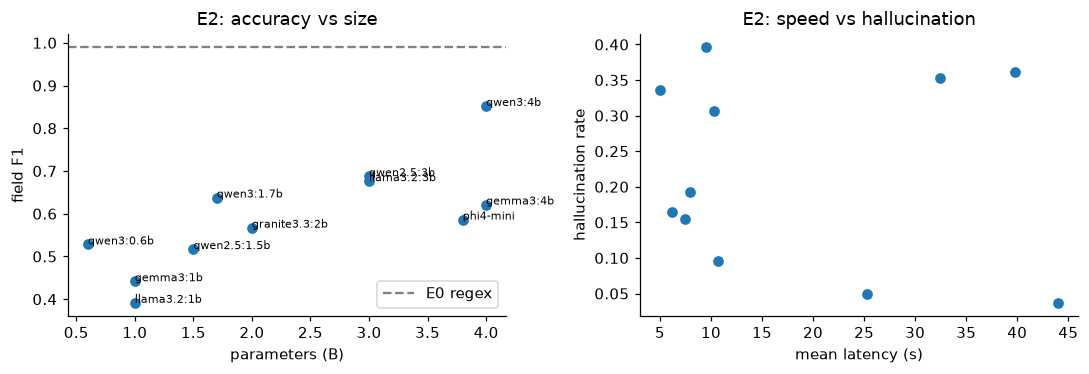

,model,think,n,valid_rate,usable_rate,field_f1,hallucination_rate,exact_match,correction_accuracy,triage_accuracy,under_triage_rate,silent_under_triage_rate,over_triage_rate,latency_mean_s,note,params_b
7,qwen3:4b,off,200,0.905,1.000,0.8522,0.0369,0.01,0.1579,0.830,0.080,0.0,0.090,44.00,NaN,4.0
8,qwen2.5:3b,NaN,200,0.630,0.975,0.6879,0.0954,0.00,0.0000,0.710,0.165,0.0,0.120,10.70,NaN,3.0
9,llama3.2:3b,NaN,200,0.860,0.980,0.6762,0.0487,0.00,0.0526,0.705,0.130,0.0,0.135,25.24,NaN,3.0
2,qwen3:1.7b,off,200,0.160,0.995,0.6379,0.1544,0.00,0.0000,0.535,0.025,0.0,0.440,7.44,NaN,1.7
10,gemma3:4b,NaN,200,0.035,1.000,0.6216,0.3609,0.00,0.0000,0.745,0.065,0.0,0.190,39.76,NaN,4.0
11,phi4-mini,NaN,200,0.070,0.955,0.5863,0.3527,0.00,0.0263,0.655,0.095,0.0,0.245,32.47,NaN,3.8


In [40]:
from scripts.sweep import DEFAULT
print("models:", DEFAULT)
def mock_e2():
    size = {"0.6b": .6, "1b": 1, "1.5b": 1.5, "1.7b": 1.7, "2b": 2, "3b": 3, "4b": 4, "mini": 3.8}
    rows = []
    for m in DEFAULT:
        s = next((v for k, v in size.items() if m.endswith(k)), 3)
        f1 = min(.97, .62 + .07 * s + MOCK.uniform(-.04, .04))
        rows.append({"model": m, "params_b": s, "field_f1": round(f1, 3),
                     "hallucination_rate": round(max(.002, .08 - .015 * s + MOCK.uniform(-.01, .01)), 3),
                     "triage_accuracy": round(min(.98, f1 - .03 + MOCK.uniform(-.02, .02)), 3),
                     "latency_mean_s": round(1.2 * s + MOCK.uniform(0, 1.5), 1)})
    return pd.DataFrame(rows)
e2, is_mock = load_or_mock("runs/sweep_dev_k0.csv", mock_e2)
if not is_mock and len(e2) < len(DEFAULT):
    print(f"(partial: {len(e2)} of {len(DEFAULT)} models done so far)")
if not is_mock:
    e2 = e2[e2.field_f1.notna() & e2.note.isna()]   # only models that completed all 200 cases
    print(e2[["model", "valid_rate", "usable_rate", "field_f1", "hallucination_rate", "triage_accuracy",
              "under_triage_rate", "over_triage_rate", "silent_under_triage_rate", "latency_mean_s"]]
          .to_string(index=False))
if "params_b" not in e2:                       # real sweep table: read the size from the model tag
    e2["params_b"] = e2.model.str.extract(r"(\d+(?:\.\d+)?)b")[0].astype(float).fillna(3.8)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].scatter(e2.params_b, e2.field_f1)
for _, r in e2.iterrows(): ax[0].annotate(r.model, (r.params_b, r.field_f1), fontsize=7)
ax[0].axhline(rep["overall"]["field_f1"], color="gray", ls="--", label="E0 regex"); ax[0].legend()
ax[0].set(xlabel="parameters (B)", ylabel="field F1", title="E2: accuracy vs size")
ax[1].scatter(e2.latency_mean_s, e2.hallucination_rate)
ax[1].set(xlabel="mean latency (s)", ylabel="hallucination rate", title="E2: speed vs hallucination")
for a in ax: mock_banner(a, is_mock)
plt.tight_layout(); plt.show()
e2.sort_values("field_f1", ascending=False).head(6)

### E2 full dev: the finalists on all 1,482 dev cases

The 200-case screen picks the finalists; the full dev split gives their final zero-shot
numbers (narrower confidence intervals). The first 200 cases are reused, so only the
other 1,282 are new. The table fills in as each model finishes.

In [41]:
full = ROOT / "runs" / "sweep_dev_k0_nall.csv"
screen = pd.read_csv(ROOT / "runs" / "e2_screen_200" / "sweep_dev_k0.csv").set_index("model")
FINALISTS = ["qwen3:1.7b", "qwen2.5:3b", "llama3.2:3b", "qwen3:4b"]
done = pd.read_csv(full).set_index("model") if full.exists() else pd.DataFrame()
cols = ["n", "valid_rate", "usable_rate", "field_f1", "hallucination_rate", "triage_accuracy",
        "under_triage_rate", "over_triage_rate", "silent_under_triage_rate", "latency_mean_s"]
rows = []
for m in FINALISTS:
    if m in done.index:
        r = done.loc[m, cols].to_dict()
        r["F1 on 200 (screen)"] = screen.loc[m, "field_f1"]
        rows.append({"model": m, "status": "done", **r})
    else:
        rows.append({"model": m, "status": "running / queued"})
pd.DataFrame(rows).set_index("model")

,status,n,valid_rate,usable_rate,field_f1,hallucination_rate,triage_accuracy,under_triage_rate,over_triage_rate,silent_under_triage_rate,latency_mean_s,F1 on 200 (screen)
model,,,,,,,,,,,,
qwen3:1.7b,done,1482.0,0.1167,0.9966,0.6269,0.1465,0.5142,0.0324,0.4507,0.0,7.38,0.6379
qwen2.5:3b,done,1482.0,0.5715,0.9696,0.6674,0.1037,0.7422,0.1599,0.0951,0.0,11.35,0.6879
llama3.2:3b,done,1482.0,0.7949,0.9696,0.6532,0.0466,0.7011,0.1296,0.1404,0.0,25.31,0.6762
qwen3:4b,done,1482.0,0.9022,0.9993,0.8315,0.0448,0.8489,0.0789,0.0709,0.0,43.83,0.8522


**Qwen3 1.7B on full dev:** field F1 0.627 (0.638 on the 200-case screen), triage
accuracy 51.4% (53.5%), over-triage 45.1%, silent under-triage 0. The full-dev numbers
are within about 2 points of the screen, so the 200-case screen was a fair sample.

**Qwen2.5 3B on full dev:** field F1 0.667 (0.688 on the screen), triage accuracy 74.2%
(71.0%), under-triage 16.0%, over-triage 9.5%, silent 0. Unlike the small models, its
errors lean towards **under**-triage: it misses findings more than it invents them, and
the engine catches every one as a provisional decision.

**Llama 3.2 3B on full dev:** field F1 0.653 (0.676 on the screen), triage accuracy 70.1%
(70.5%), under-triage 13.0%, over-triage 14.0%, silent 0, 25 s/case. It has the lowest
hallucination rate of the finalists so far (4.7%) and the highest strict-valid rate (79.5%),
and it gets the most corrections right (8.1%), though that is still very low.

**Three smaller finalists:** every model scores 1–2 F1 points lower on full dev than on
the screen, and the order stays the same: Qwen2.5 3B > Llama 3.2 3B > Qwen3 1.7B on F1. The
models fail in different ways. Qwen3 1.7B over-triages (it invents findings), Qwen2.5 3B
under-triages (it misses them), and Llama 3.2 3B sits in between with the fewest invented
details. None of them handles spoken corrections ("BP 95, correction 85"): this is the
clearest target for E3 few-shot. Silent under-triage is still 0 for every model, so the
engine catches every missed finding as a provisional decision.

**Qwen3 4B on full dev:** field F1 0.832 (0.852 on the screen), triage accuracy 84.9%
(83.0%), under-triage 7.9%, over-triage 7.1%, silent 0, hallucination 4.5%, usable 99.9%,
44 s per case. It is the best finalist on every measure except speed, and the only one with
balanced errors. It gets the most corrections right (14.0%), but that is still low.

**E2 conclusion (all 4 finalists done):** the full-dev ranking is the same as the screen's
(Qwen3 4B > Qwen2.5 3B > Llama 3.2 3B > Qwen3 1.7B on F1), and every model is 1–2 F1 points
lower, so screening on 200 cases was safe. Zero-shot, the best model reaches F1 0.83 and
triage 84.9%, against 0.99 and 95.3% for the (optimistic) regex baseline. Almost no record is
fully right (exact match below 1%), and spoken corrections are the weakest skill for every
model. These are the targets for E3 (few-shot) and E4 (fine-tuning). The run took about 30 h
of laptop time over two days; it was stopped and resumed eight times without redoing a case.

### E2 run status: what is done, what is left, and why we stopped

**The sweep finished on 2026-11-02** (all 12 models). It was stopped three times on the way:

1. **The 3–4B models are too slow on this laptop.** At 4-bit they need more than the
   4 GB of GPU memory, so Ollama puts part of the model on the CPU. Qwen3 4B took
   **~40 s per case** (vs 5–7 s for the 1–2B models), about 3 hours per model for 200
   cases. We first paused the five 3–4B models, then ran them after the small
   models (the whole capped run took about 8 hours on the laptop).
2. **The laptop ran out of memory.** Claude Code stopped the small-model run when
   system RAM was almost full (other programs were using most of the 32 GB).
3. **We stopped by hand** to free the laptop, partway through Gemma 3 1B (it was
   resumed later and finished).

**Nothing is lost.** `extract/run.py` appends one line per case and skips cases already
in the file, so re-running the same command continues from the next case.

The cell below reads the saved run files and builds the status table directly from them,
so it is always up to date. For a partial run it also scores the cases done so far. These are **interim** numbers on fewer than 200 cases. They are not in the ranking
above.

In [42]:
import csv as _csv
from scripts.sweep import tag
from extract.score import score as _score
done_rows = {r["model"]: r for r in _csv.DictReader(open(ROOT / "runs/sweep_dev_k0.csv", encoding="utf-8"))} \
    if (ROOT / "runs/sweep_dev_k0.csv").exists() else {}
PAUSED_3_4B = set()                               # empty now: the 3-4B models were paused, then run
status, interim = [], []
for m in DEFAULT:
    f = ROOT / "runs" / f"{tag(m, 'dev', 0)}.jsonl"
    n = sum(1 for _ in open(f, encoding="utf-8")) if f.exists() else 0
    row = done_rows.get(m)
    if row and row["note"]:
        st, why = "dropped", row["note"]
    elif row:
        st, why = "done", "200 cases scored"
    elif m in PAUSED_3_4B:
        st, why = "paused", "3-4B: spills to CPU on the 4 GB GPU (~40 s/case)"
    elif n:
        st, why = "in progress", "not yet at 200 cases"
    else:
        st, why = "not started", "queued"
    status.append({"model": m, "status": st, "cases_done": n, "reason": why})
    if n and not row:                              # interim score of a partial run
        r, _ = _score(f, ROOT / "examples/synthetic_handovers_v2.csv", "dev", subset=True)
        o = r["overall"]
        interim.append({"model": m, "n": n, **{k: round(o[k], 3) for k in
                        ("usable_rate", "field_f1", "hallucination_rate", "triage_accuracy",
                         "over_triage_rate", "silent_under_triage_rate")},
                        "latency_mean_s": round((r["latency_s"] or {}).get("mean", 0), 1)})
print(pd.DataFrame(status).to_string(index=False))
print("\nInterim scores of partial runs (fewer than 200 cases, not final):")
print(pd.DataFrame(interim).to_string(index=False) if interim else "(none)")

        model  status  cases_done                                             reason
   qwen3:0.6b    done         200                                   200 cases scored
   qwen3:1.7b    done        1482                                   200 cases scored
     qwen3:4b    done        1482                                   200 cases scored
 qwen2.5:1.5b    done         200                                   200 cases scored
   qwen2.5:3b    done        1482                                   200 cases scored
  llama3.2:1b    done         200                                   200 cases scored
  llama3.2:3b    done        1482                                   200 cases scored
    gemma3:1b    done         200                                   200 cases scored
    gemma3:4b    done         200                                   200 cases scored
    phi4-mini    done         200                                   200 cases scored
 smollm2:1.7b dropped          50 stopped after smoke: usable 0.7

**How it was run** (dev split only; the test set is not touched). The same command
resumes a stopped run:

```
python scripts/sweep.py --models qwen3:0.6b qwen3:1.7b qwen3:4b qwen2.5:1.5b qwen2.5:3b llama3.2:1b
                                 llama3.2:3b gemma3:1b gemma3:4b phi4-mini smollm2:1.7b granite3.3:2b
```

Next, the finalists get the full dev set (`--limit 0`, results in
`runs/sweep_dev_k0_nall.csv`; see the full-dev section below), then error analysis.

**First pass: three models were dropped by the smoke-test gate**, not by us: Llama 3.2
1B, Qwen2.5 1.5B and SmolLM2 1.7B. Each had at least one case where the model never
stopped writing and the request ran into the 600 s timeout (SmolLM2 had 7+).

**A problem with the gate, and the fix.** One runaway case cost 10 minutes and removed
the whole model, even if the other 49 cases were fine (Qwen2.5 1.5B scored like Qwen3
0.6B). So we changed the rule for **all** models:

- Output is capped at **1,500 tokens** (`extract/run.py --max-tokens`, sent to Ollama as
  `num_predict`). A normal record is 530–900 tokens; for every model 99% of outputs are
  under 1,000. A runaway now stops within seconds and is scored as one invalid output.
- The smoke gate looks at the **mean** time per case, not the slowest case.
- The 21 cases that had gone over 1,500 tokens or timed out (in five models) were
  deleted and re-run under the cap, so every model is scored under the same rule. The
  old files are kept in `runs/archive_pre_cap/`.

**After the fix:** Llama 3.2 1B and Qwen2.5 1.5B passed and finished 200 cases. SmolLM2
1.7B was dropped again, this time fairly: only 78% of its outputs are usable. Qwen3
1.7B and Gemma 3 1B barely changed (F1 0.639 → 0.638 and 0.440 → 0.442).

### E2 error analysis: where Qwen3 4B still goes wrong

**Module: `scripts/error_analysis.py`.** The scorer gives one outcome per field and
case. This script reads those outcomes and the raw outputs, and checks a list of
**error patterns** that we found by reading Qwen3 4B's full-dev mistakes. Each pattern
is a fixed rule, so the same table can be built for any run. That lets us compare models
now, and prompt changes (E3) and fine-tuning (E4) later. Dev only.

| Function | How it works |
|---|---|
| `load(pred_path, split)` | runs `score()` to get the per-case outcomes, and also parses every raw output and gold record, so the patterns can look at values as well as outcomes |
| `filled(record)` | counts the non-null leaves; a record with 3 or fewer from a full handover is an **empty record** |
| `correction_kind(gold, pred, r)` | sorts one spoken correction into: fully right, value right but log in words, value right but not logged, kept the retracted value, value left null, other |
| `analyse(pred_path, split)` | computes every pattern as hits / cases where it can happen, lists the criteria lost in each under-triaged case (gold record vs model record through the engine), and writes `per_field.csv`, `under_triage.csv`, `corrections.csv` and `summary.json` to `runs/error_analysis/<run>/` |
| `main()` | runs `analyse` on each run given and writes one comparison table, `runs/error_analysis/patterns_dev.csv` |

In [43]:
import scripts.error_analysis as EA
show_code(EA.correction_kind)
RUNS = {m: ROOT / "runs" / f"{tag(m, 'dev', 0)}.jsonl" for m in FINALISTS}
if all(p.exists() for p in RUNS.values()):
    EA_SUM = {m: EA.analyse(p, "dev") for m, p in RUNS.items()}
    pat = pd.DataFrame({m: {k: v["rate"] for k, v in s["patterns"].items() if isinstance(v, dict) and "rate" in v}
                        for m, s in EA_SUM.items()})
    display(pat.round(3))
else:
    EA_SUM = None
    print("full-dev runs not found; run scripts/sweep.py --limit 0 first")

# scripts\error_analysis.py:62
  62  def correction_kind(g, p, r):
  63      """How one spoken correction was handled (r is a gold retraction entry)."""
  64      if p is None:
  65          return "no usable output"
  66      value_ok = norm(get(p, r["field"])) == norm(get(g, r["field"]))
  67      logs = p["retractions"]
  68      if value_ok and any(norm(x) == norm(r) for x in logs):
  69          return "fully right"
  70      if value_ok and any(re.search("[a-z]", f"{x['retracted_value']}{x['corrected_value']}") for x in logs):
  71          return "value right, log in words"
  72      if value_ok and logs:
  73          return "value right, log entry wrong"
  74      if value_ok:
  75          return "value right, not logged"
  76      if str(get(p, r["field"])) == r["retracted_value"]:
  77          return "kept the retracted value"
  78      if get(p, r["field"]) is None:
  79          return "value left null"
  80      return "other wrong value"


,qwen3:1.7b,qwen2.5:3b,llama3.2:3b,qwen3:4b
empty_record,0.003,0.030,0.038,0.020
empty_record_vitals_first,0.200,0.311,0.561,0.867
gcs_total_only_missed,0.015,0.928,0.759,0.478
gcs_with_components_missed,0.002,0.653,0.272,0.033
no_loc_missed,0.878,0.991,0.926,0.713
impact_speed_missed,0.162,0.215,0.976,0.753
burn_mechanism_missed,0.000,0.086,0.924,0.857
amputation_region_hand_or_foot,0.425,0.875,0.775,1.000
sbp_110_119_read_as_1x0,0.465,0.360,0.000,0.524
hemorrhage_none_unsaid,0.059,0.159,0.151,0.723


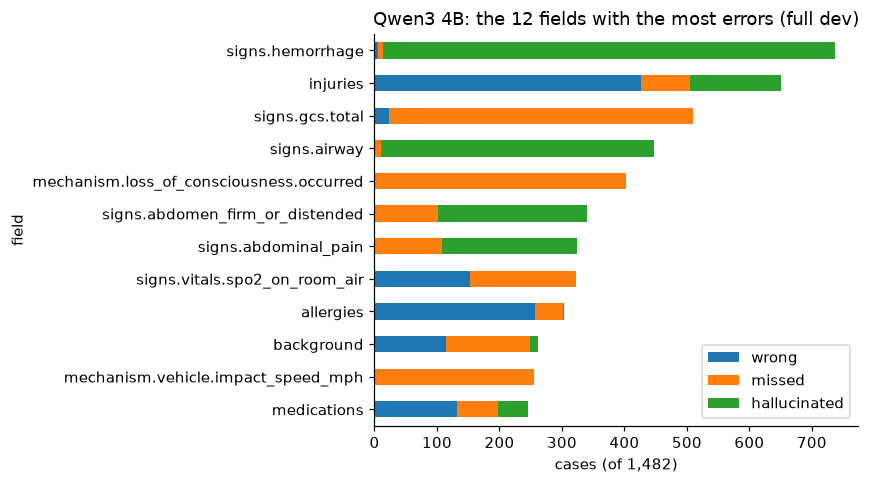

,spoken corrections
kind,
"value right, log in words",122
kept the retracted value,79
fully right,40
value left null,22
"value right, not logged",15
other wrong value,5
"value right, log entry wrong",2


under-triaged cases: 117, from empty records: 22, all provisional: True
criteria lost most often: [('L3-05', 35), ('L2-04', 26), ('L3-02', 11), ('L1-09', 7), ('L1-15', 6), ('L3-01', 6)]


In [44]:
if EA_SUM:
    d = ROOT / "runs" / "error_analysis" / "qwen3-4b_dev_k0"
    pf = pd.read_csv(d / "per_field.csv").set_index("field").head(12)
    ax = pf[["wrong", "missed", "hallucinated"]].iloc[::-1].plot.barh(stacked=True, figsize=(8, 4.5))
    ax.set(xlabel="cases (of 1,482)", title="Qwen3 4B: the 12 fields with the most errors (full dev)")
    plt.tight_layout(); plt.show()
    corr = pd.read_csv(d / "corrections.csv")
    display(corr.kind.value_counts().to_frame("spoken corrections"))
    ut = pd.read_csv(d / "under_triage.csv").fillna("")
    lost = collections.Counter(x for s in ut.criteria_lost for x in s.split())
    print(f"under-triaged cases: {len(ut)}, from empty records: {ut.empty_record.sum()}, "
          f"all provisional: {bool(ut.provisional.all())}")
    print("criteria lost most often:", lost.most_common(6))

**What the analysis shows (Qwen3 4B, 1,482 dev cases).** Most errors are **systematic**:
a few habits repeat across many cases. They are not random noise.

1. **A nested object left null when only part of it was said.**
   - "GCS fifteen" with no eye/verbal/motor breakdown: the whole `gcs` object is null in
     48% of cases (3% when the components are given).
   - "No loss of consciousness": `loss_of_consciousness` is null in 71% of cases.
   - Crash speed: missed in 75% of cases. The `vehicle` object is left null, always so
     for pedestrian and cyclist crashes.
   - "With burns" but `mechanism.type` null: 86%.

   These four are the largest source of **missed** fields.
2. **Digit amputations put on the hand or foot.** "Amputation of four fingers on the
   right hand" is written as region `hand` in 100% of cases, so L3-05 (2 or more digits)
   never fires. This **one convention causes 35 of the 117 under-triaged cases**.
3. **"One-fourteen" read as 140.** For a systolic BP of 110–119, the model writes
   (x − 100) × 10 in 52% of cases. No triage threshold sits there, but it is a real
   number-reading failure.
4. **"Normal" values that nobody said**, against rule 1 of the prompt:
   - `hemorrhage "none"` in 72% of the cases where bleeding was not mentioned;
   - `airway "patent"` in 43%;
   - abdominal pain false in 19%.

   These make up most of the 4.5% hallucination rate. They do not change the level,
   but they **hide unknowns from the engine**, so it asks fewer questions. That is the
   kind of error the safety property depends on not happening.
5. **Empty records.** In 30 cases (2%) the model returns an all-null record. 26 of the 30
   are calls that **open with the vital signs** before the story.
6. **Corrections.**
   - The corrected **value** is right in 63% of cases.
   - The 14% "correction accuracy" is low mainly because the retraction log is written
     in **words** ("thirty-five") instead of digits: 122 of 285 corrections.
   - In 79 corrections the model **kept the retracted value**. This happens in 38% of
     the corrections that cross a triage threshold.

**Under-triage.** Empty records, the amputation region, the missing crash speed and
the missing LOC together explain **85 of the 117** under-triaged cases (73%). Every one
of the 117 was a provisional decision with a question for the medic: none was silent.

**The other finalists share some patterns and not others.**
- **Shared by all four:**
  - the LOC object is dropped (71–99%);
  - amputations are put on the hand or foot (43–100%);
  - corrections are often kept wrong.
- **Specific to one model:**
  - Llama 3.2 3B never misreads "one-fourteen" but misses crash speed 98% of the time;
  - Qwen3 1.7B rarely drops GCS or speed, but writes `trend "stable"` 70% of the time
    when no trend was said.

So the fixes should target the patterns, not one model.

**What this means for E3 and later.** The obvious fixes are:
- **Prompt conventions:**
  - digits are region `finger`/`toe`;
  - "GCS 15" fills `gcs.total`;
  - "no LOC" fills `occurred: false`;
  - crash speed always goes in `vehicle`;
  - burns set `mechanism.type`;
  - retraction values are digits;
  - leave hemorrhage and airway null unless they are mentioned.
- **Few-shot examples** with vitals-first calls and corrections.
- **A deterministic post-step** that converts number words in the retraction log to
  digits, like the repair step.

The prompt changes are an E3 ablation. Any change to the post-processing changes the
scoring rules, so it has to be applied to every model and reported separately.

## E3: few-shot and prompt ablations

**Question.** How much do in-context examples (k = 0, 1, 2, 4 from the **train** set,
via `--fewshot k`) and individual prompt parts (the conventions block, the
correction rule) help? Is it worth the extra prompt tokens and latency on a small
device?

MOCK DATA (no runs/sweep_fewshot_summary.csv yet): placeholder values for illustration only


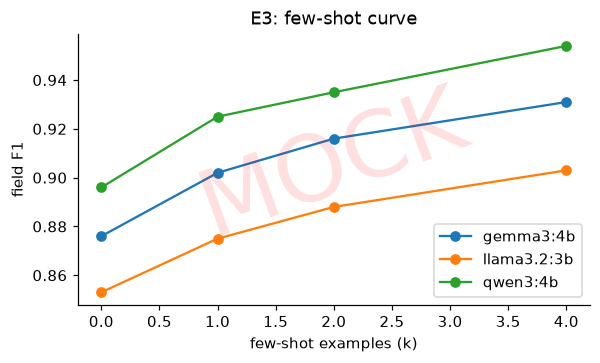

,ablation,Δ field F1 (mock),Δ correction acc (mock)
0,full prompt,0.000,0.000
1,- conventions block,-0.031,-0.004
2,- correction rule,-0.012,-0.210
3,- field hints,-0.018,-0.010


In [45]:
def mock_e3():
    rows = []
    for m, base in (("qwen3:4b", .90), ("gemma3:4b", .88), ("llama3.2:3b", .85)):
        for k in (0, 1, 2, 4):
            rows.append({"model": m, "k": k, "field_f1": round(min(.985, base + .025 * (k ** .5) + MOCK.uniform(-.005, .005)), 3)})
    return pd.DataFrame(rows)
e3, is_mock = load_or_mock("runs/sweep_fewshot_summary.csv", mock_e3)
fig, ax = plt.subplots(figsize=(6, 3.2))
for m, g in e3.groupby("model"): ax.plot(g.k, g.field_f1, marker="o", label=m)
ax.set(xlabel="few-shot examples (k)", ylabel="field F1", title="E3: few-shot curve"); ax.legend(); mock_banner(ax, is_mock); plt.show()
pd.DataFrame({"ablation": ["full prompt", "- conventions block", "- correction rule", "- field hints"],
              "Δ field F1 (mock)": [0, -.031, -.012, -.018], "Δ correction acc (mock)": [0, -.004, -.21, -.01]})

## E4: fine-tuning and the data-size curve

**Question.** Does fine-tuning (QLoRA, then full fine-tuning for the smallest
models) on **template-only** data transfer to the natural v2 speech style? How
many training cases are needed?

Training sizes are 250 → 10,000 cases from `synthetic_handovers_train_v0.csv`.
The gap between template-style dev (v0) and Claude-style dev (v2) measures
**style generalisation**. A large gap would argue for adding paraphrased training
data, using a non-Claude paraphraser to keep independence.

MOCK DATA (no runs/e4_datasize.csv yet): placeholder values for illustration only


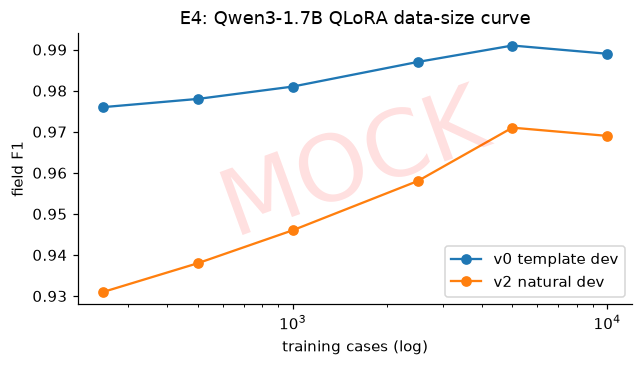

In [46]:
def mock_e4():
    rows = []
    for n in (250, 500, 1000, 2500, 5000, 10000):
        for style, off in (("v0 template dev", 0), ("v2 natural dev", .045)):
            f1 = .995 - .25 / (n ** .45) - off * (1 - min(n, 5000) / 9000)
            rows.append({"n_train": n, "eval": style, "field_f1": round(f1 + MOCK.uniform(-.004, .004), 3)})
    return pd.DataFrame(rows)
e4, is_mock = load_or_mock("runs/e4_datasize.csv", mock_e4)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
for s, g in e4.groupby("eval"): ax.plot(g.n_train, g.field_f1, marker="o", label=s)
ax.set_xscale("log"); ax.set(xlabel="training cases (log)", ylabel="field F1", title="E4: Qwen3-1.7B QLoRA data-size curve")
ax.legend(); mock_banner(ax, is_mock); plt.show()

## E5: quantisation trade-off

**Question.** How much accuracy is lost at 8-, 5- and 4-bit? Smaller weights mean
the model fits cheaper hardware (an ambulance tablet, an ED workstation).

MOCK DATA (no runs/e5_quant.csv yet): placeholder values for illustration only


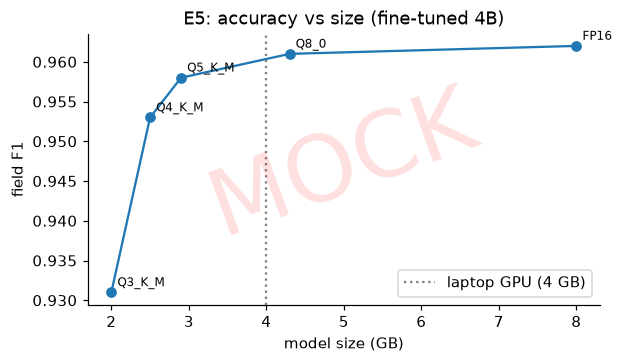

In [47]:
def mock_e5():
    return pd.DataFrame({"quant": ["FP16", "Q8_0", "Q5_K_M", "Q4_K_M", "Q3_K_M"],
                         "size_gb": [8.0, 4.3, 2.9, 2.5, 2.0],
                         "field_f1": [.962, .961, .958, .953, .931],
                         "tokens_per_s": [9, 22, 31, 35, 38]})
e5, is_mock = load_or_mock("runs/e5_quant.csv", mock_e5)
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(e5.size_gb, e5.field_f1, marker="o")
for _, r in e5.iterrows(): ax.annotate(r.quant, (r.size_gb, r.field_f1), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax.axvline(4, color="gray", ls=":", label="laptop GPU (4 GB)"); ax.legend()
ax.set(xlabel="model size (GB)", ylabel="field F1", title="E5: accuracy vs size (fine-tuned 4B)"); mock_banner(ax, is_mock); plt.show()

## E6: final test (run once)

The 3–5 finalists run **once** on the frozen test set (1,518 synthetic cases + the
real recordings) after all choices are made on dev. First,
`python scripts/freeze_test.py --verify` must print "test set intact". The headline
table reports each metric with a 95% CI. The key safety metric is **silent
under-triage**.

In [48]:
print("MOCK test table (* = real dev number for E0, not test)")
pd.DataFrame({
    "system": ["E0 regex", "zero-shot best (E2)", "few-shot best (E3)", "fine-tuned 1.7B (E4)", "fine-tuned 4B Q4 (E5)"],
    "field F1": ["0.99*", "0.90", "0.94", "0.97", "0.96"],
    "triage acc": ["0.95*", "0.88", "0.92", "0.96", "0.95"],
    "silent under-triage": ["0*", "0.4%", "0.2%", "0", "0"],
})

MOCK test table (* = real dev number for E0, not test)


,system,field F1,triage acc,silent under-triage
0,E0 regex,0.99*,0.95*,0*
1,zero-shot best (E2),0.90,0.88,0.4%
2,few-shot best (E3),0.94,0.92,0.2%
3,fine-tuned 1.7B (E4),0.97,0.96,0
4,fine-tuned 4B Q4 (E5),0.96,0.95,0


## E7: robustness to speech-recognition errors

**Question.** What happens when the text comes from Whisper instead of a perfect
transcript?
- **Plan:** synthesise audio of the v2 texts with TTS, add radio-band noise at several
  signal-to-noise ratios, transcribe with Whisper (`scripts/transcribe.py`), and run
  the extractor.
- **Measures:** word error rate (WER) vs field F1 and vs triage accuracy, especially
  on numbers ("fifteen" vs "fifty"), the most dangerous type of error.

MOCK DATA (no runs/e7_asr_noise.csv yet): placeholder values for illustration only


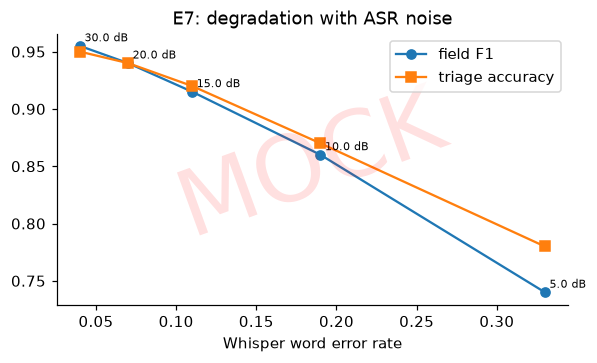

In [49]:
def mock_e7():
    snr = [30, 20, 15, 10, 5]
    return pd.DataFrame({"snr_db": snr, "wer": [.04, .07, .11, .19, .33],
                         "field_f1": [.955, .94, .915, .86, .74], "triage_acc": [.95, .94, .92, .87, .78]})
e7, is_mock = load_or_mock("runs/e7_asr_noise.csv", mock_e7)
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(e7.wer, e7.field_f1, marker="o", label="field F1"); ax.plot(e7.wer, e7.triage_acc, marker="s", label="triage accuracy")
for _, r in e7.iterrows(): ax.annotate(f"{r.snr_db} dB", (r.wer, r.field_f1), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(xlabel="Whisper word error rate", title="E7: degradation with ASR noise"); ax.legend(); mock_banner(ax, is_mock); plt.show()

## E8 / E9: audio-in models and deployment

- **E8 (optional):** audio-native models that skip the separate Whisper step.
  Compare against Whisper → SLM.
- **E9:** latency and memory on target hardware, from the laptop (RTX 3050 Ti) down
  to CPU-only. Budget: the record and level must be ready well before the
  ambulance arrives. Real ETAs in the data are 3–25 minutes, so the target is a
  few seconds.

MOCK DATA (no runs/e9_deploy.csv yet): placeholder values for illustration only


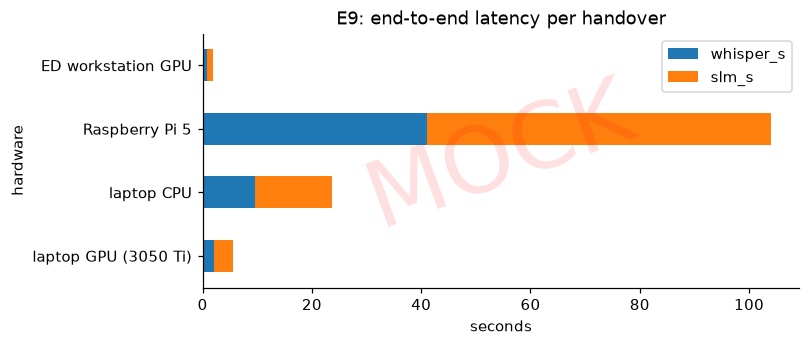

In [50]:
def mock_e9():
    return pd.DataFrame({"hardware": ["laptop GPU (3050 Ti)", "laptop CPU", "Raspberry Pi 5", "ED workstation GPU"],
                         "whisper_s": [2.1, 9.5, 41, .8], "slm_s": [3.4, 14.2, 63, 1.1]})
e9, is_mock = load_or_mock("runs/e9_deploy.csv", mock_e9)
ax = e9.set_index("hardware")[["whisper_s", "slm_s"]].plot.barh(stacked=True, figsize=(7, 3), title="E9: end-to-end latency per handover")
ax.set_xlabel("seconds"); mock_banner(ax, is_mock); plt.show()

---
## Summary and open items

**Done**
- The schema and 37 criteria.
- A labelled synthetic corpus: 3,000 dev/test cases in 3 styles and 10,000 template training cases.
- The real recordings transcribed.
- A frozen, hash-verified test set.
- A three-valued rule engine with zero silent under-triage on incomplete records.
- Prompt schema, scorer and inference harness.
- The E0 baseline.
- An audited and repaired v2 label set.

**Next**
1. E2 is done: Qwen3 4B is best (F1 0.85, triage 83%, hallucination 3.7%); 11 of 12
   models finished, SmolLM2 dropped. Finalists: Qwen3 4B, Qwen2.5 3B, Llama 3.2 3B and
   Qwen3 1.7B.
2. Full dev done (1,482 cases, 2026-11-04): Qwen3 4B F1 0.832, triage 84.9%. Error
   analysis done (`scripts/error_analysis.py`): most errors are a few systematic habits;
   four of them explain 73% of Qwen3 4B's under-triage.
3. E3 few-shot and prompt ablations on the finalists, aimed at those patterns
   (conventions for GCS/LOC/speed/burns/amputations, digits in the retraction log,
   vitals-first examples).


**Open items**
- Clinician sign-off on engine assumptions A1–A6.
- Hand-check about 50 v2 texts for realism.
- Update the AI-use declaration.
- Choose the compute source for fine-tuning (university HPC, cloud or Kaggle).
- Real-data access (MIMIC-IV-ED / NEMSIS) to replace the hand-set case distributions.